In [1]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ==================================================
# TEMA GLOBAL BASADO EN PALETA EQUINOR
# ==================================================

equinor_palette = {
    "energy_red": "#EB0037",
    "white": "#FFFFFF",
    "mist_blue": "#D5EAF4",
    "heritage_red": "#990024",
    "slate_grey": "#6F6F6F",
    "pickled_bluewood": "#253747"
}

# Paleta principal para gráficos
PALETA = [
    equinor_palette["energy_red"],
    equinor_palette["mist_blue"],
    equinor_palette["slate_grey"],
    equinor_palette["heritage_red"],
    equinor_palette["pickled_bluewood"]
]

# Tema seaborn global
sns.set_theme(
    style="whitegrid",
    context="talk",
    palette=PALETA
)

# Ajustes matplotlib globales
plt.rcParams["figure.figsize"] = (10,6)
plt.rcParams["figure.facecolor"] = equinor_palette["white"]
plt.rcParams["axes.facecolor"] = equinor_palette["white"]

plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlecolor"] = equinor_palette["pickled_bluewood"]

plt.rcParams["axes.labelsize"] = 12
plt.rcParams["axes.labelcolor"] = equinor_palette["pickled_bluewood"]

plt.rcParams["xtick.labelsize"] = 11
plt.rcParams["ytick.labelsize"] = 11
plt.rcParams["xtick.color"] = equinor_palette["slate_grey"]
plt.rcParams["ytick.color"] = equinor_palette["slate_grey"]

plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["grid.color"] = equinor_palette["slate_grey"]

plt.rcParams["legend.frameon"] = False
plt.rcParams["text.color"] = equinor_palette["pickled_bluewood"]

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.edgecolor"] = equinor_palette["slate_grey"]

# Heatmap Equinor
CMAP_HEATMAP = LinearSegmentedColormap.from_list(
    "equinor_heatmap",
    [
        equinor_palette["mist_blue"],
        equinor_palette["white"],
        equinor_palette["energy_red"],
        equinor_palette["heritage_red"]
    ]
)

## 1. Carga y Comprensión de Datos
Se carga el dataset `global_supply_chain_risk_2026.csv` que contiene registros de envíos internacionales con variables operativas, climáticas y geopolíticas. El objetivo es comprender su estructura antes de cualquier transformación.

In [3]:
# Ajusta la ruta si el CSV está en otra carpeta
df = pd.read_csv("global_supply_chain_risk_2026.csv")
df

,Shipment_ID,Date,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Disruption_Occurred
0,SC-10000,2025-10-16,Singapore,Los Angeles,Rail,Textiles,5930.83,197.42,2.43,5.0,Hurricane,0.865,41.39,1
1,SC-10001,2024-04-24,Singapore,Shanghai,Rail,Automotive,14285.36,237.24,2.30,7.5,Storm,0.592,40.92,1
2,SC-10002,2024-01-26,Rotterdam,Los Angeles,Rail,Perishables,11113.91,427.42,1.78,5.6,Rain,0.673,11.54,0
3,SC-10003,2024-10-08,Busan,Hamburg,Rail,Electronics,9180.55,170.66,3.20,0.8,Hurricane,0.832,53.13,1
4,SC-10004,2024-09-07,Busan,Singapore,Air,Perishables,2762.27,434.96,2.77,1.9,Fog,0.741,0.50,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,SC-14995,2025-11-10,Rotterdam,Dubai,Rail,Perishables,13512.26,428.97,3.35,8.8,Fog,0.664,20.28,0
4996,SC-14996,2025-11-23,Dubai,Shanghai,Air,Perishables,2231.02,448.86,1.79,0.5,Clear,0.863,0.50,0
4997,SC-14997,2025-10-18,Antwerp,Busan,Rail,Pharmaceuticals,5253.72,473.41,1.37,3.0,Clear,0.962,4.41,0
4998,SC-14998,2025-01-29,Singapore,Dubai,Rail,Automotive,12328.31,199.35,3.45,4.4,Storm,0.819,31.18,1


In [4]:
# Asegurar formato datetime
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Extraer años únicos
years = df['Date'].dt.year.dropna().unique()

print("Años en el dataset:", sorted(years))

# Rango (mínimo y máximo)
print("Desde:", df['Date'].min())
print("Hasta:", df['Date'].max())

Años en el dataset: [np.int32(2024), np.int32(2025)]
Desde: 2024-01-01 00:00:00
Hasta: 2025-12-31 00:00:00


In [5]:
#df.tail()
#df.head()
#df.info()
#df.describe()
#df.shape
#df.dtypes
#df.nunique()
df


,Shipment_ID,Date,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Disruption_Occurred
0,SC-10000,2025-10-16,Singapore,Los Angeles,Rail,Textiles,5930.83,197.42,2.43,5.0,Hurricane,0.865,41.39,1
1,SC-10001,2024-04-24,Singapore,Shanghai,Rail,Automotive,14285.36,237.24,2.30,7.5,Storm,0.592,40.92,1
2,SC-10002,2024-01-26,Rotterdam,Los Angeles,Rail,Perishables,11113.91,427.42,1.78,5.6,Rain,0.673,11.54,0
3,SC-10003,2024-10-08,Busan,Hamburg,Rail,Electronics,9180.55,170.66,3.20,0.8,Hurricane,0.832,53.13,1
4,SC-10004,2024-09-07,Busan,Singapore,Air,Perishables,2762.27,434.96,2.77,1.9,Fog,0.741,0.50,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,SC-14995,2025-11-10,Rotterdam,Dubai,Rail,Perishables,13512.26,428.97,3.35,8.8,Fog,0.664,20.28,0
4996,SC-14996,2025-11-23,Dubai,Shanghai,Air,Perishables,2231.02,448.86,1.79,0.5,Clear,0.863,0.50,0
4997,SC-14997,2025-10-18,Antwerp,Busan,Rail,Pharmaceuticals,5253.72,473.41,1.37,3.0,Clear,0.962,4.41,0
4998,SC-14998,2025-01-29,Singapore,Dubai,Rail,Automotive,12328.31,199.35,3.45,4.4,Storm,0.819,31.18,1


## 2. Limpieza de Datos
### 2.1 Revisión de Valores Faltantes
Se identifican columnas con datos nulos para decidir si se imputan o eliminan, garantizando la integridad del análisis posterior.

In [6]:
#Contar valores nulos
df.isnull().sum()
#En caso de haber valores nulos se debe calcular el porcengtaje de valores faltantes
(df.isnull().sum() / len(df)) * 100

Shipment_ID                  0.0
Date                         0.0
Origin_Port                  0.0
Destination_Port             0.0
Transport_Mode               0.0
Product_Category             0.0
Distance_km                  0.0
Weight_MT                    0.0
Fuel_Price_Index             0.0
Geopolitical_Risk_Score      0.0
Weather_Condition            0.0
Carrier_Reliability_Score    0.0
Lead_Time_Days               0.0
Disruption_Occurred          0.0
dtype: float64

### 2.2 Busqueda de valores NaN

In [7]:
df.isna()
df[df.isna().any(axis=1)]

,Shipment_ID,Date,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Disruption_Occurred


### 2.3 Busqueda de valores duplicados


In [8]:
df.duplicated().sum()

np.int64(0)

### 2.4 Corrección de tipos de datos

In [9]:
df.dtypes

Shipment_ID                             str
Date                         datetime64[us]
Origin_Port                             str
Destination_Port                        str
Transport_Mode                          str
Product_Category                        str
Distance_km                         float64
Weight_MT                           float64
Fuel_Price_Index                    float64
Geopolitical_Risk_Score             float64
Weather_Condition                       str
Carrier_Reliability_Score           float64
Lead_Time_Days                      float64
Disruption_Occurred                   int64
dtype: object

In [10]:
# Convertir tipo de dato de objeto a datetimek 
df['Date'] = pd.to_datetime(df['Date']).dt.normalize()
df.info()
df['Date']


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Shipment_ID                5000 non-null   str           
 1   Date                       5000 non-null   datetime64[us]
 2   Origin_Port                5000 non-null   str           
 3   Destination_Port           5000 non-null   str           
 4   Transport_Mode             5000 non-null   str           
 5   Product_Category           5000 non-null   str           
 6   Distance_km                5000 non-null   float64       
 7   Weight_MT                  5000 non-null   float64       
 8   Fuel_Price_Index           5000 non-null   float64       
 9   Geopolitical_Risk_Score    5000 non-null   float64       
 10  Weather_Condition          5000 non-null   str           
 11  Carrier_Reliability_Score  5000 non-null   float64       
 12  Lead_Time_Days   

0      2025-10-16
1      2024-04-24
2      2024-01-26
3      2024-10-08
4      2024-09-07
          ...    
4995   2025-11-10
4996   2025-11-23
4997   2025-10-18
4998   2025-01-29
4999   2024-06-01
Name: Date, Length: 5000, dtype: datetime64[us]

In [11]:
cols = ['Origin_Port','Destination_Port','Transport_Mode','Product_Category','Weather_Condition']

df[cols] = (
    df[cols]
    .astype(str)
    .apply(lambda x: x.str.strip().str.lower())
    .astype('category')
)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Shipment_ID                5000 non-null   str           
 1   Date                       5000 non-null   datetime64[us]
 2   Origin_Port                5000 non-null   category      
 3   Destination_Port           5000 non-null   category      
 4   Transport_Mode             5000 non-null   category      
 5   Product_Category           5000 non-null   category      
 6   Distance_km                5000 non-null   float64       
 7   Weight_MT                  5000 non-null   float64       
 8   Fuel_Price_Index           5000 non-null   float64       
 9   Geopolitical_Risk_Score    5000 non-null   float64       
 10  Weather_Condition          5000 non-null   category      
 11  Carrier_Reliability_Score  5000 non-null   float64       
 12  Lead_Time_Days   

### 2.5 Eliminar espacios en todas las columnas categoricas y convertir a minusculas

In [12]:
# limpiar nombres
df.columns = df.columns.str.strip().str.lower()

# columnas correctas
cols = [
    'origin_port',
    'destination_port',
    'transport_mode',
    'product_category',
    'weather_condition'
]

# verificar
print([col for col in cols if col not in df.columns])


[]


In [13]:
df.columns = df.columns.str.strip().str.lower()

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   shipment_id                5000 non-null   str           
 1   date                       5000 non-null   datetime64[us]
 2   origin_port                5000 non-null   category      
 3   destination_port           5000 non-null   category      
 4   transport_mode             5000 non-null   category      
 5   product_category           5000 non-null   category      
 6   distance_km                5000 non-null   float64       
 7   weight_mt                  5000 non-null   float64       
 8   fuel_price_index           5000 non-null   float64       
 9   geopolitical_risk_score    5000 non-null   float64       
 10  weather_condition          5000 non-null   category      
 11  carrier_reliability_score  5000 non-null   float64       
 12  lead_time_days   

### 2.6 Auditoria. Análisis y validación de variables categóricas.

¿Qué valores existen?

In [15]:
categorical_cols = [
    "origin_port",
    "destination_port",
    "transport_mode",
    "product_category",
    "weather_condition"
]

for col in categorical_cols:
    display(pd.DataFrame({
        "columna": col,
        "valores_unicos": df[col].unique()
    }))

,columna,valores_unicos
0,origin_port,singapore
1,origin_port,rotterdam
2,origin_port,busan
3,origin_port,shanghai
4,origin_port,dubai
5,origin_port,los angeles
6,origin_port,hamburg
7,origin_port,antwerp


,columna,valores_unicos
0,destination_port,los angeles
1,destination_port,shanghai
2,destination_port,hamburg
3,destination_port,singapore
4,destination_port,marseille
5,destination_port,antwerp
6,destination_port,rotterdam
7,destination_port,busan
8,destination_port,dubai


,columna,valores_unicos
0,transport_mode,rail
1,transport_mode,air
2,transport_mode,road
3,transport_mode,sea


,columna,valores_unicos
0,product_category,textiles
1,product_category,automotive
2,product_category,perishables
3,product_category,electronics
4,product_category,pharmaceuticals


,columna,valores_unicos
0,weather_condition,hurricane
1,weather_condition,storm
2,weather_condition,rain
3,weather_condition,fog
4,weather_condition,clear


¿Qué tan frecuente es cada valor?

In [16]:
for col in categorical_cols:
    display(
        df[col]
        .value_counts()
        .rename_axis(col)
        .reset_index(name="frecuencia")
    )

,origin_port,frecuencia
0,busan,667
1,rotterdam,646
2,shanghai,644
3,antwerp,635
4,dubai,610
5,los angeles,602
6,singapore,599
7,hamburg,597


,destination_port,frecuencia
0,marseille,583
1,rotterdam,574
2,busan,570
3,shanghai,561
4,dubai,559
5,antwerp,552
6,los angeles,537
7,hamburg,536
8,singapore,528


,transport_mode,frecuencia
0,air,1320
1,sea,1281
2,road,1214
3,rail,1185


,product_category,frecuencia
0,electronics,1016
1,textiles,1010
2,perishables,1009
3,pharmaceuticals,1006
4,automotive,959


,weather_condition,frecuencia
0,fog,1036
1,storm,1002
2,clear,995
3,hurricane,990
4,rain,977


¿Cuántas categorías hay?

In [17]:
summary = pd.DataFrame({
    "columna": categorical_cols,
    "n_categorias": [df[col].nunique() for col in categorical_cols]
})

display(summary)

,columna,n_categorias
0,origin_port,8
1,destination_port,9
2,transport_mode,4
3,product_category,5
4,weather_condition,5


### 2.7 Resumen final, Sumarizado de valores únicos.

In [18]:
final_summary = pd.DataFrame({
    "columna": categorical_cols,
    "n_categorias": [df[col].nunique() for col in categorical_cols],
    "valores_unicos": [list(df[col].unique()) for col in categorical_cols]
})

display(final_summary)

,columna,n_categorias,valores_unicos
0,origin_port,8,"[singapore, rotterdam, busan, shanghai, dubai,..."
1,destination_port,9,"[los angeles, shanghai, hamburg, singapore, ma..."
2,transport_mode,4,"[rail, air, road, sea]"
3,product_category,5,"[textiles, automotive, perishables, electronic..."
4,weather_condition,5,"[hurricane, storm, rain, fog, clear]"


### 2.8 Verificación de outliers

In [19]:
df.describe()


,date,distance_km,weight_mt,fuel_price_index,geopolitical_risk_score,carrier_reliability_score,lead_time_days,disruption_occurred
count,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2025-01-04 20:34:04.800000,7704.063888,246.252052,2.854552,5.076900,0.754387,19.355386,0.612600
min,2024-01-01 00:00:00,500.170000,1.030000,1.200000,0.000000,0.500000,0.500000,0.000000
25%,2024-07-03 00:00:00,4036.010000,124.330000,2.020000,2.600000,0.629000,2.110000,0.000000
50%,2025-01-06 00:00:00,7750.125000,243.500000,2.840000,5.100000,0.757000,8.245000,1.000000
75%,2025-07-09 00:00:00,11347.462500,366.955000,3.710000,7.500000,0.879000,21.207500,1.000000
max,2025-12-31 00:00:00,14995.910000,499.750000,4.500000,10.000000,1.000000,236.390000,1.000000
std,NaN,4199.687885,142.522591,0.959533,2.877832,0.144363,31.405143,0.487205


In [20]:
numerical_cols = [
    "distance_km",
    "weight_mt",
    "fuel_price_index",
    "geopolitical_risk_score",
    "carrier_reliability_score",
    "lead_time_days"
]

outliers_summary = []

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    outliers_summary.append({
        "variable":         col,
        "outliers":         len(outliers),
        "limite_inferior":  lower,
        "limite_superior":  upper
    })

outliers_df = pd.DataFrame(outliers_summary)


# ──────────────────────────────────────────────────────────────────────────────
print("Decisión sobre outliers: SE MANTIENEN como señal operativa real.")
print("Justificación: los valores extremos de lead_time reflejan disrupciones,")
print("no errores de medición (Tukey, 1977; Barnett & Lewis, 1994).")
print()
outliers_df


Decisión sobre outliers: SE MANTIENEN como señal operativa real.
Justificación: los valores extremos de lead_time reflejan disrupciones,
no errores de medición (Tukey, 1977; Barnett & Lewis, 1994).



,variable,outliers,limite_inferior,limite_superior
0,distance_km,0,-6931.16875,22314.64125
1,weight_mt,0,-239.60750,730.89250
2,fuel_price_index,0,-0.51500,6.24500
3,geopolitical_risk_score,0,-4.75000,14.85000
4,carrier_reliability_score,0,0.25400,1.25400
5,lead_time_days,518,-26.53625,49.85375



Decisión adoptada: MANTENER los outliers y tratarlos como señal de riesgo.
Fundamento: en logística los valores extremos de lead_time no son errores de medición sino eventos reales (disrupciones, retrasos severos) que son exactamente lo que queremos modelar.
 Referencia: Tukey, J.W. (1977). Exploratory Data Analysis, cap. 2.

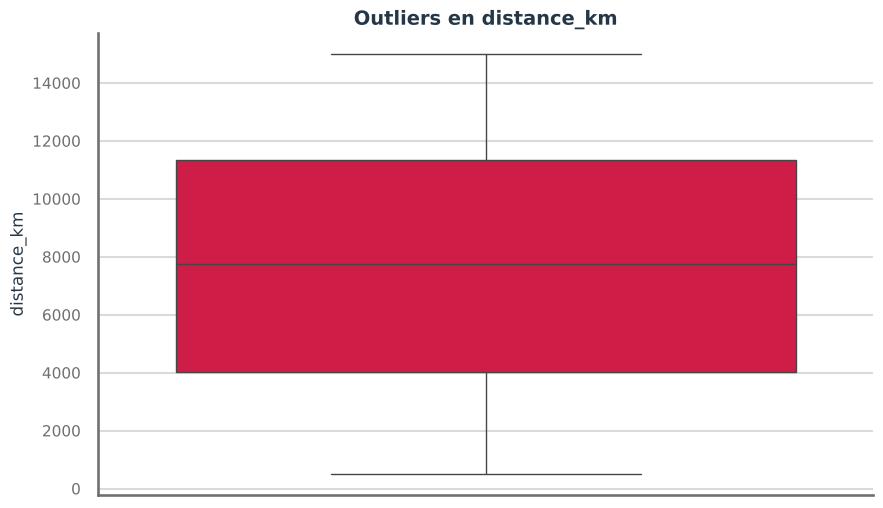

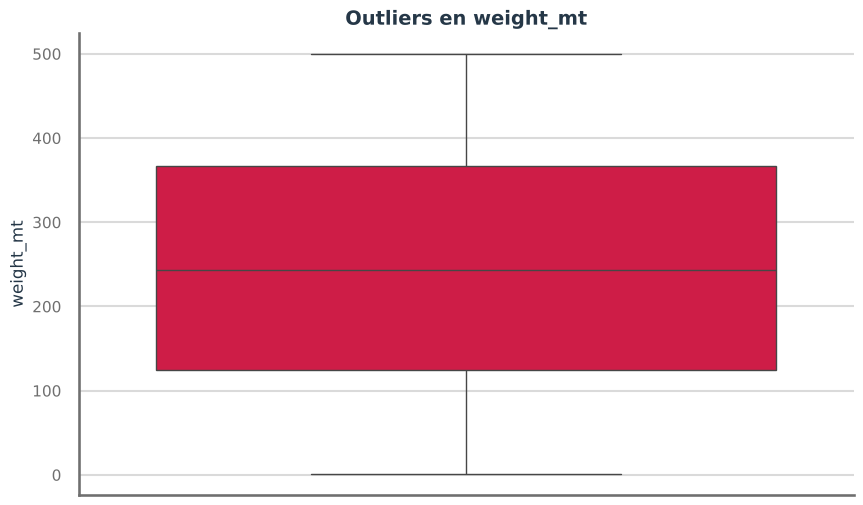

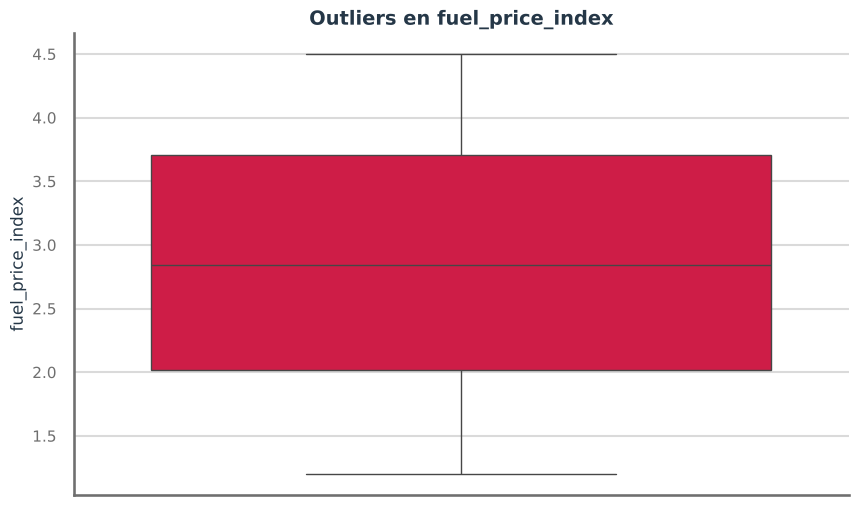

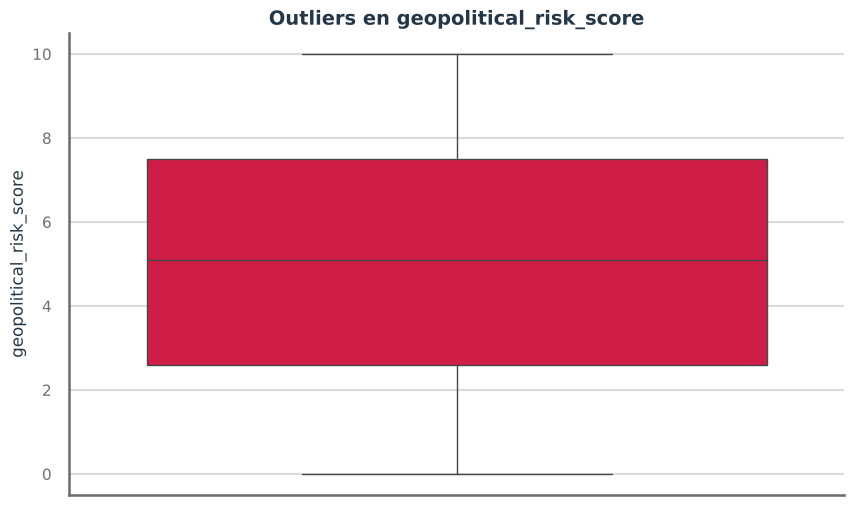

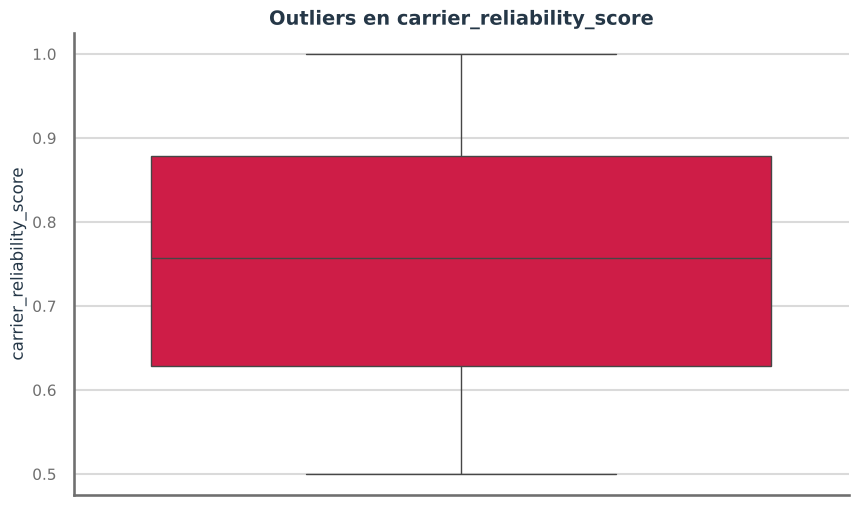

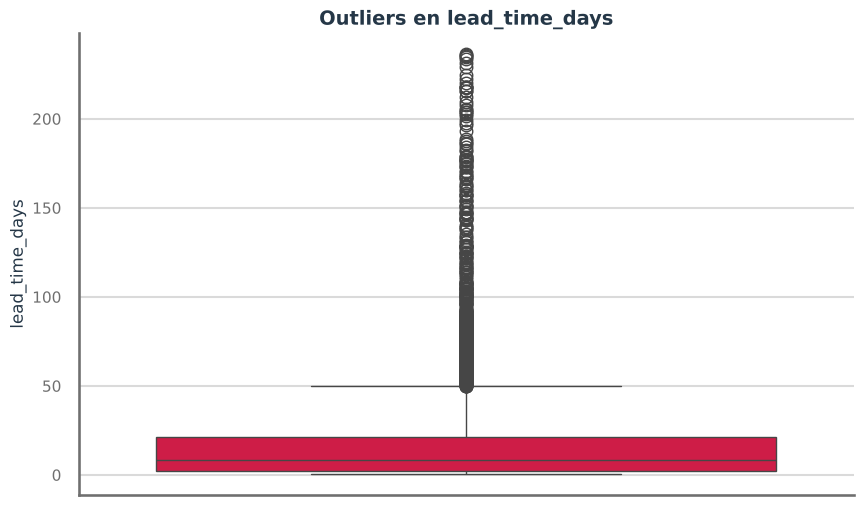

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

for col in numerical_cols:
    plt.figure()
    sns.boxplot(y=df[col])
    plt.title(f"Outliers en {col}")
    plt.show()

In [22]:
df_outliers = df[df["lead_time_days"] > 50]

In [23]:
df_outliers.groupby("transport_mode",observed=True).size()

transport_mode
rail    124
road    102
sea     291
dtype: int64

El análisis de valores atípicos en el tiempo de entrega muestra que el transporte marítimo presenta la mayor cantidad de retrasos extremos, lo que indica un mayor riesgo operativo. En contraste, el transporte aéreo no presenta valores atípicos, posicionándose como la opción más confiable en términos de tiempo de entrega

## 3. Validación de consistencia del dataset

### 3.1 ¿Los datos tienen sentido lógico entre sí?

In [24]:
summary = pd.DataFrame({
    "columna": df.columns,
    "nulos": df.isnull().sum(),
    "tipo": df.dtypes,
    "valores_unicos": df.nunique()
})

summary

,columna,nulos,tipo,valores_unicos
shipment_id,shipment_id,0,str,5000
date,date,0,datetime64[us],731
origin_port,origin_port,0,category,8
destination_port,destination_port,0,category,9
transport_mode,transport_mode,0,category,4
product_category,product_category,0,category,5
distance_km,distance_km,0,float64,4998
weight_mt,weight_mt,0,float64,4785
fuel_price_index,fuel_price_index,0,float64,331
geopolitical_risk_score,geopolitical_risk_score,0,float64,101


Se realizó una validación de consistencia del dataset, verificando valores nulos, rangos lógicos, duplicados y coherencia entre variables. No se identificaron inconsistencias críticas, por lo que los datos se consideran aptos para el análisis exploratorio.

## 4. Análisis Exploratorio de Datos (EDA)

<p style="font-size:18px;">
Con el dataset previamente limpio y validado, el análisis se enfoca en identificar riesgos operativos, evaluar su impacto y generar insights para la toma de decisiones estratégicas en la cadena de suministro.
</p>

### 4.1 EDA DESCRIPTIVO. Identificación de riesgos
#### ¿Dónde está el problema?


Separación automática de variables numéricas y categóricas en función de su tipo de dato, con el objetivo de aplicar técnicas de análisis específicas a cada tipo de variable. Se realiza esta transformación para evitar errores y asegurar que variables categóricas puedan ser utilizadas en cálculos y modelos, ya que muchos métodos analíticos requieren variables numéricas.

In [25]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns

/tmp/ipykernel_225/3894701945.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object', 'category']).columns


#### Cuantificación de la variable clima. Codificación ordinal

Se mapean los valores reales del dataset en orden ordinal de severidad.

**Fundamento:** codificación ordinal basada en severidad meteorológica real (escala Beaufort / clasificación NWS (National Wether Service) de impacto operativo). Clear < Fog < Rain < Storm < Hurricane (impacto logístico creciente).

**Referencia:** ISO 31000:2018 §6.4.2 — identificación exhaustiva de fuentes de riesgo.

In [26]:
weather_map = {
    'clear':     0,   # sin riesgo meteorológico
    'fog':       1,   # visibilidad reducida — riesgo bajo
    'rain':      2,   # riesgo moderado
    'storm':     3,   # riesgo alto
    'hurricane': 4    # riesgo máximo (tasa de disrupción real = 100%)
}

df['weather_severity'] = df['weather_condition'].str.lower().map(weather_map)

# ── Prueba de integridad (buena práctica) ────────────────────────────────────
nulos_clima = df['weather_severity'].isna().sum()
assert nulos_clima == 0, f"ERROR: {nulos_clima} valores de clima sin mapear → revisar weather_map"
print("✓ Todos los valores de weather_condition mapeados correctamente.")
print(df.groupby('weather_condition',observed=True)['weather_severity'].first().sort_values())


✓ Todos los valores de weather_condition mapeados correctamente.
weather_condition
clear        0
fog          1
rain         2
storm        3
hurricane    4
Name: weather_severity, dtype: int64


La cuantificación del clima se basa en una codificación ordinal, donde se asignan valores numéricos según el nivel de severidad, permitiendo incorporar esta variable en el modelo de forma coherente con su impacto en el riesgo.

### 4.2 Normalización de Variables
**Normalización de variables** (llevana una escala comparable (0–1)) y construcción del índice de impacto (**Risk Scoring Model**),basado en un modelo de scoring (**ISO 31000, OECD**). **Fórmula estándar min-max: (x - min) / (max - min)**

***Referencia:** OECD (2008). Handbook on Constructing Composite Indicators, §3.
Esta **normalización garantiza** que todas las variables estén en [0, 1],lo cual es requisito para sumarlas con pesos de forma coherente.

In [27]:
def minmax(series):
    """Normalización min-max estándar → escala [0, 1]."""
    return (series - series.min()) / (series.max() - series.min())

df['lead_time_norm'] = minmax(df['lead_time_days'])
df['geo_norm']       = minmax(df['geopolitical_risk_score'])
df['carrier_norm']   = 1 - minmax(df['carrier_reliability_score'])  # invertido: mayor confiabilidad = menor riesgo
df['weather_norm']   = df['weather_severity'] / df['weather_severity'].max()

print("Rangos tras normalización (deben ser [0.0 – 1.0]):")
for col in ['lead_time_norm','geo_norm','carrier_norm','weather_norm']:
    print(f"  {col}: [{df[col].min():.3f}, {df[col].max():.3f}]")


Rangos tras normalización (deben ser [0.0 – 1.0]):
  lead_time_norm: [0.000, 1.000]
  geo_norm: [0.000, 1.000]
  carrier_norm: [0.000, 1.000]
  weather_norm: [0.000, 1.000]


Es un modelo de scoring estándar en gestión de riesgos (ISO 31000) y en índices compuestos (OECD, 2008).

df['carrier_norm'] = 1 - df['carrier_reliability_score']  # ya invertido

**Justificación de la inversión de carrier_norm:**
Se aplica la transformación **1 - minmax** para garantizar la homogeneidad direccional del modelo. Mientras que las demás variables miden riesgo de forma directa (a mayor valor, peor escenario), una alta confiabilidad del transportista representa un escenario positivo. Al invertirla, se transforma en una métrica de "riesgo de incumplimiento", alineando todas las variables bajo el mismo **criterio:** 0 es óptimo y 1 es riesgo máximo, permitiendo su correcta agregación en el índice compuesto.

### 4.3 Cálculo del Índice de Impacto y Riesgo Logístico

In [28]:
df['impact'] = (
    df['lead_time_norm'] * 0.4 +
    df['geo_norm'] * 0.3 +
    df['carrier_norm'] * 0.2 +
    df['weather_norm'] * 0.1
)

**Justificación de Ponderadores del Índice de Riesgo**

Los pesos asignados se basan en el conocimiento del dominio logístico y son consistentes con la metodología de indicadores compuestos de la OECD (2008). Bajo este enfoque, no existe una única asignación óptima; los pesos deben reflejar la relevancia operativa real de cada factor.

La asignación no responde únicamente a correlaciones estadísticas, sino al impacto operativo directo de cada variable:

  **• Lead time (0.4):** Afecta directamente los niveles de servicio (SLA) y costos de almacenamiento. Representa el peso máximo.

  **• Riesgo geopolítico (0.3):** Determina la viabilidad estratégica y continuidad a largo plazo de la ruta. Representa un peso alto.

  **• Confiabilidad del transportista (0.2):** Define la predictibilidad y control directo sobre la ejecución física del envío. 
Representa un peso moderado.

  **• Clima (0.1):** Posee un alto impacto estadístico coyuntural, pero un bajo control operativo por parte de la empresa. Representa un peso conservador.

Este equilibrio entre evidencia empírica y juicio experto es el estándar recomendado para la construcción de índices compuestos (OECD, 2008, §5.3). La robustez de estos pesos puede validarse posteriormente mediante un análisis de sensibilidad.

#### ¿Qué variables explican el fenómeno?, exploración de relaciones.

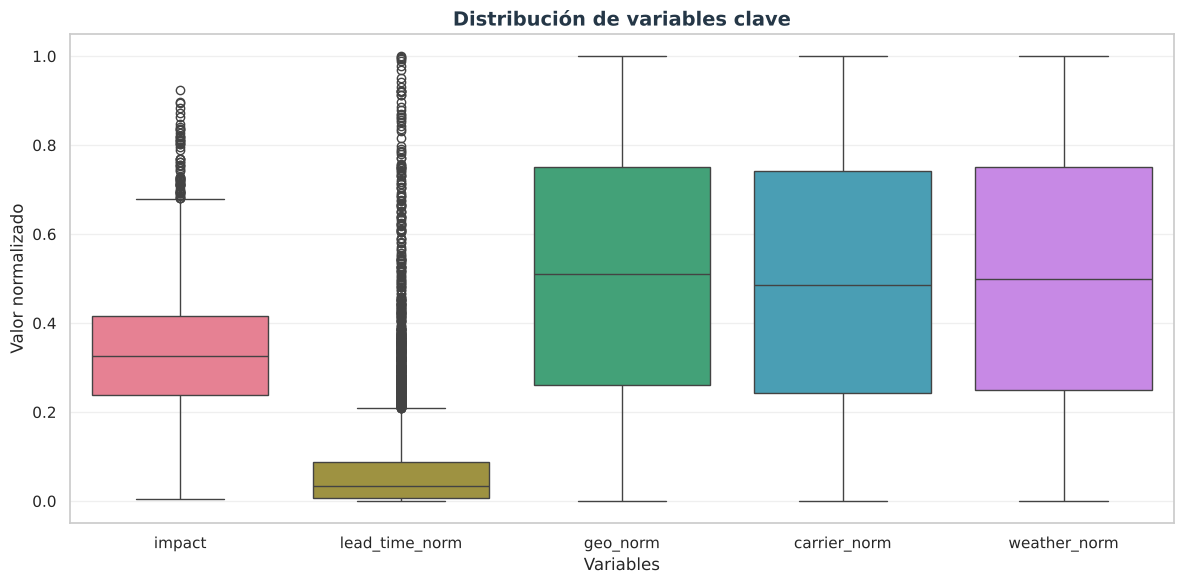

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

# Estilo general único
sns.set_theme(style="whitegrid", palette=["#c31566", "#6e6e6e"])

# Variables a comparar
cols = ['impact', 'lead_time_norm', 'geo_norm', 'carrier_norm', 'weather_norm']

# Boxplots de todas las variables
plt.figure(figsize=(12,6))

sns.boxplot(
    data=df[cols],
   
)

plt.title("Distribución de variables clave", fontsize=14, fontweight="bold")
plt.xlabel("Variables")
plt.ylabel("Valor normalizado")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**• impact (Rosa):** Tiene una distribución balanceada, centrada en un riesgo moderado-bajo (mediana en ~0.33), con valores atípicos (outliers) concentrados únicamente en la parte superior **(riesgo muy alto)**.

**• lead_time_norm (Marrón)**: Esta es la variable clave. Al contrario de lo que dice tu texto actual, su distribución está sesgada hacia abajo (valores mínimos). La caja es sumamente compacta cerca de 0.0, lo que significa que la gran mayoría de tus envíos tienen tiempos de entrega óptimos. Los "valores extremos" (los puntos negros que suben en vertical) representan casos aislados donde el tiempo de entrega se disparó masivamente.

**• geo_norm, carrier_norm y weather_norm:** Muestran distribuciones muy similares entre sí, con una dispersión amplia y cajas simétricas bien distribuidas a lo largo de la escala de 0 a 1.

El diagrama de caja **• lead_time_norm (Marrón)** revela una alta concentración de datos en los niveles inferiores y una densa presencia de valores atípicos (outliers) en la parte superior. Para corregir este sesgo y profundizar en el comportamiento de estos eventos extremos, se procedió a aplicar una **transformación logarítmica**. Esta técnica permitió estabilizar la varianza y descubrir —como se demuestra analíticamente en la siguiente gráfica de dispersión— que dichos valores atípicos corresponden a retrasos críticos que actúan como detonantes directos de las disrupciones en la ruta.


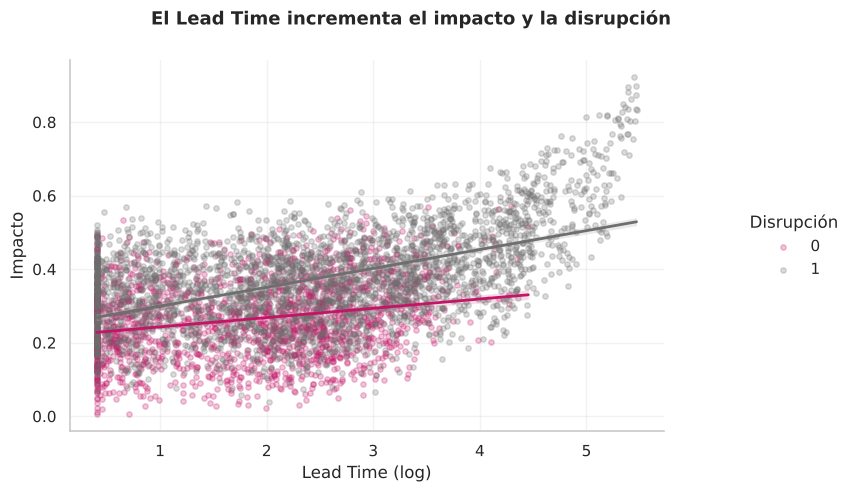

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Crear columna correcta si no existe
if 'lead_time_log' not in df.columns:
    df['lead_time_log'] = np.log1p(df['lead_time_days'])


# Gráfico
g = sns.lmplot(
    data=df,
    x='lead_time_log',
    y='impact',
    hue='disruption_occurred',
    height=5,
    aspect=1.4,
    scatter_kws={'alpha':0.25, 's':15},
    line_kws={'linewidth':2}
)

g.set_axis_labels('Lead Time (log)', 'Impacto')

g.fig.suptitle(
    'El Lead Time incrementa el impacto y la disrupción',
    fontsize=13,
    fontweight='bold'
)

g.fig.subplots_adjust(top=0.88)

if g._legend:
    g._legend.set_title('Disrupción')

plt.show()

### 4.4 Análisis de Relación: Lead Time vs. Impacto y Disrupción

El gráfico de dispersión confirma empíricamente la solidez del índice compuesto y valida la transformación logarítmica aplicada sobre el *Lead Time*:

* **Comportamiento Lineal:** Al aplicar la escala logarítmica, se evidencia una relación lineal positiva directa entre el *Lead Time* y el nivel de **Impacto**. A medida que los tiempos de entrega se prolongan, el score de impacto global del riesgo aumenta de forma predecible.
* **Efecto de la Disrupción (Umbral Crítico):** La segmentación por color revela un patrón operativo clave:
  * Las operaciones **sin disrupción (0)** se concentran en tiempos logarítmicos bajos y mantienen el impacto controlado por debajo de 0.4.
  * Las operaciones **con disrupción (1)** se agrupan predominantemente en la zona superior derecha (valores logarítmicos altos). Esto demuestra que el retraso prolongado actúa como el principal catalizador de fallas críticas en la cadena de suministro, disparando el índice de impacto a niveles peligrosos (superiores a 0.4).

**Conclusión:** Este hallazgo justifica el peso máximo otorgado al *Lead Time* (0.4) en el diseño del indicador compuesto, consolidándolo como el predictor operativo más crítico para mitigar riesgos logísticos.

Se realizó un análisis exploratorio visual previo (pairplot) para identificar posibles relaciones entre variables, a partir del cual se seleccionaron las variables clave y se procedió con la matriz de correlación.

### 4.5 Análisis de Relación: Severidad Climática Normalizada vs. Impacto

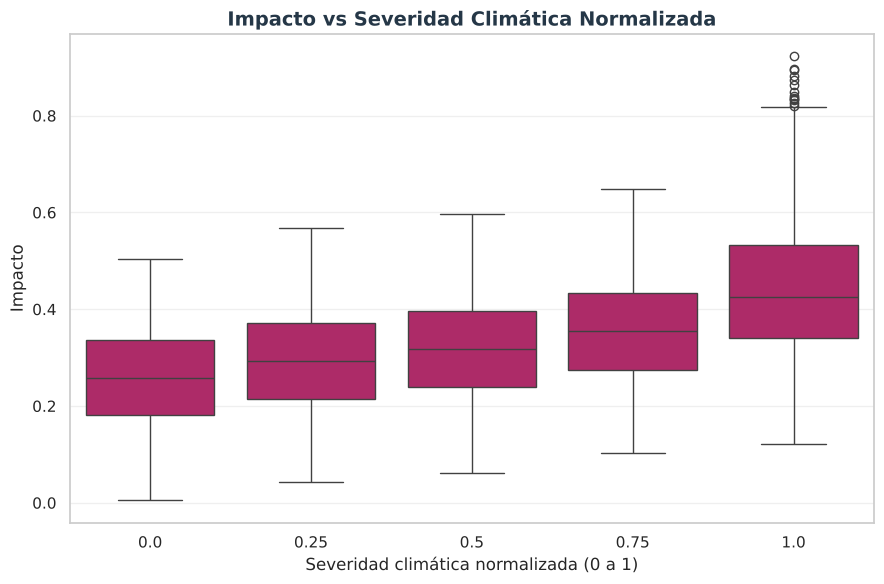

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

# Boxplot: impacto vs severidad climática normalizada
plt.figure(figsize=(9,6))

sns.boxplot(
    data=df,
    x="weather_norm",
    y="impact",
  
)

plt.title("Impacto vs Severidad Climática Normalizada", fontsize=14, fontweight="bold")
plt.xlabel("Severidad climática normalizada (0 a 1)")
plt.ylabel("Impacto")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

El impacto aumenta progresivamente con la severidad climática. Además, en todos los niveles, los eventos con disrupción presentan impactos significativamente mayores.
La severidad climática actúa como amplificador del riesgo, incrementando tanto el impacto como la volatilidad operativa

### 4.6 Análisis Multivariado: Interacción de Variables y Patrones de Disrupción

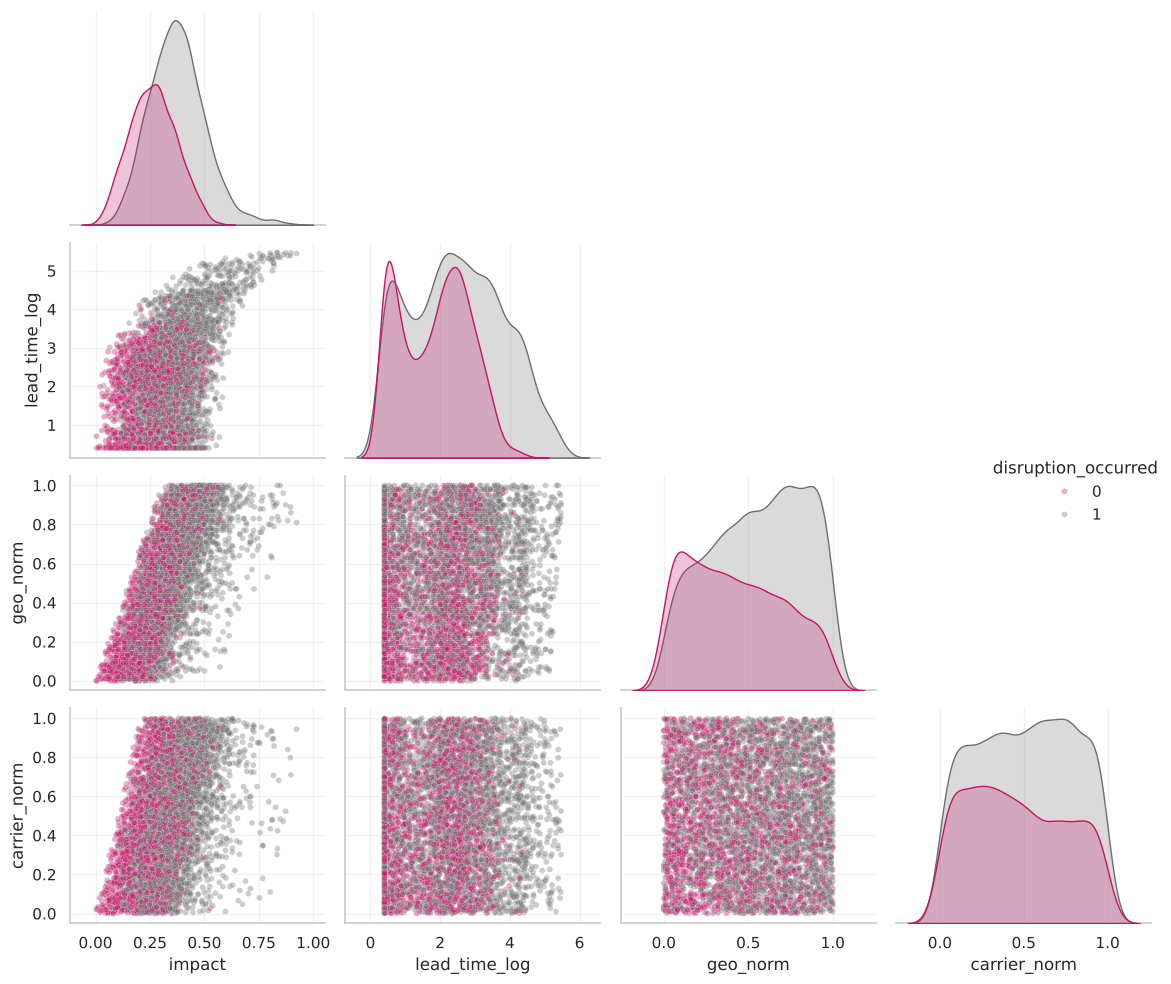

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

cols = [
    'impact',
    'lead_time_log',
    'geo_norm',
    'carrier_norm'
]  # No incluyo clima porque distorsiona el gráfico; se evaluará por separado

sns.pairplot(
    df,
    vars=cols,
    hue='disruption_occurred',
    diag_kind='kde',
    corner=True,
   #plot_kws={'alpha': 0.8, 's': 45},
   # diag_kws={'fill': True, 'alpha': 0.6}
   plot_kws={'alpha':0.35, 's':18},
   diag_kws={'fill':True},
  
)

plt.tight_layout()
plt.show()

La matriz de gráficos permite evaluar simultáneamente las distribuciones individuales y las correlaciones cruzadas de los factores de riesgo, segmentados por la presencia de disrupciones (0: No, 1: Sí).

* **Análisis de Distribuciones (Diagonal Principal):**
  * **`lead_time_log`:** Muestra una clara separación bimodal en el comportamiento operativo. Cuando la variable se desplaza hacia la derecha (valores altos en la escala logarítmica), la densidad gris (`1`) predomina, confirmando que los retrasos severos son el entorno idóneo para la falla logística.
  * **`geo_norm` y `carrier_norm`:** Las áreas grises sobresalen significativamente por encima de las rosas en los rangos altos de riesgo geopolítico y riesgo de transportista. Esto evidencia que a mayor exposición al peligro externo o peor desempeño del proveedor, la probabilidad de disrupción se incrementa de forma crítica.

* **Análisis de Dispersión y Correlación (Fuera de la Diagonal):**
  * **Relación con el Impacto:** En los cruces de `impact` con `lead_time_log` y `geo_norm`, se observa una clara frontera diagonal. Los eventos con disrupción (`1`, gris) se posicionan de forma consistente en los cuadrantes de alto impacto y alto riesgo sectorial.
  * **Independencia de Factores:** Las nubes de puntos entre `geo_norm` y `carrier_norm` muestran una dispersión uniforme y rectangular. Esto demuestra metodológicamente que ambos riesgos son independientes entre sí, validando la decisión de incluirlos como variables separadas no redundantes dentro del índice compuesto.

**Conclusión General:** El pairplot demuestra visualmente que el riesgo no es el resultado de un solo factor aislado, sino de la acumulación de vulnerabilidades. Sin embargo, la combinación de un `lead_time_log` elevado con picos en `geo_norm` o `carrier_norm` actúa como el escenario predictivo definitivo para la pérdida del nivel de servicio.


#### ¿Cuánto pesa cada variable?, cuantificación de drivers

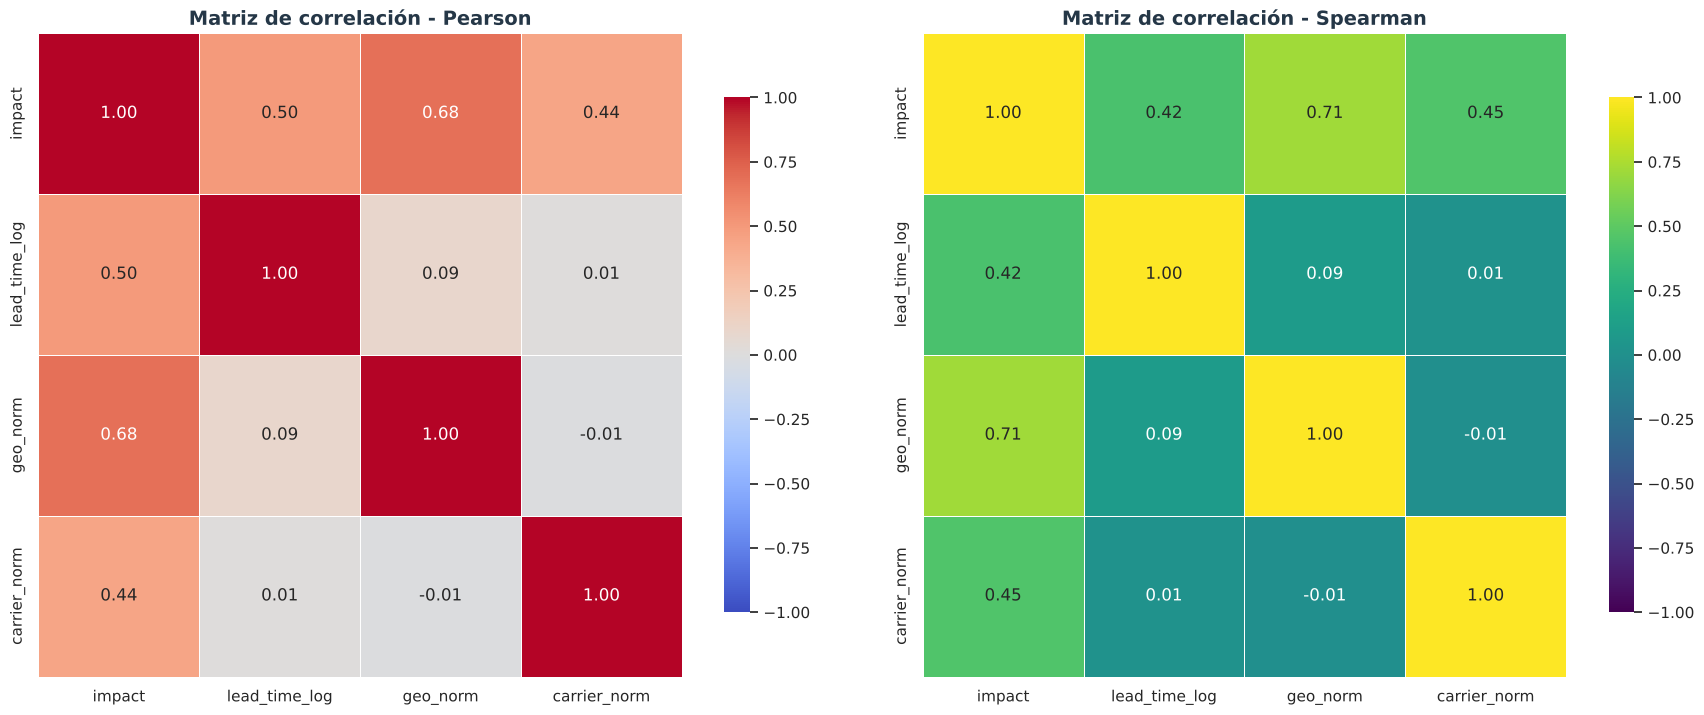

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Detectar o crear la columna de lead time (en escala log)
if 'lead_time_log' in df.columns:
    lead_col = 'lead_time_log'
elif 'lead_time_days' in df.columns:
    df['lead_time_log'] = np.log1p(df['lead_time_days'])
    lead_col = 'lead_time_log'
elif 'lead_time' in df.columns:
    df['lead_time_log'] = np.log1p(df['lead_time'])
    lead_col = 'lead_time_log'
else:
    raise KeyError("No se encontró ninguna columna de lead time")

# Variables clave
cols = ['impact', lead_col, 'geo_norm', 'carrier_norm']
data = df[cols]

corr_pearson = data.corr(method='pearson')
corr_spearman = data.corr(method='spearman')

# Configuración por panel: (matriz, título, colormap)
paneles = [
    (corr_pearson,  "Pearson",  "coolwarm"),
    (corr_spearman, "Spearman", "viridis"),
]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, (corr, title, cmap) in zip(axes, paneles):
    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap=cmap,
        vmin=-1, vmax=1,
        center=0 if cmap == "coolwarm" else None,
        linewidths=0.5,
        square=True,
        cbar_kws={"shrink": 0.8},
        ax=ax,
    )
    ax.set_title(f"Matriz de correlación - {title}", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()

### 4.7 Análisis Comparativo de Correlación: Pearson vs. Spearman

La evaluación paralela de las matrices de correlación permite validar de manera exhaustiva la estructura del modelo y la naturaleza de las relaciones entre variables:

* **Convergencia y Consistencia del Índice (`impact`):** 
  * Ambos métodos confirman que el score de **`impact`** está fuertemente respaldado por sus tres componentes individuales. 
  *El riesgo geopolítico (`geo_norm`) mantiene el liderazgo con la correlación más alta (**0.68** en Pearson y **0.71** en Spearman). La diferencia entre ambos métodos sugiere una relación monótona, pero no estrictamente lineal.
  * El tiempo de entrega (`lead_time_log`, **0.50 / 0.42**) y el riesgo del transportista (`carrier_norm`, **0.44 / 0.45**) muestran coeficientes estables y robustos en ambas métricas.

* **Ausencia de multicolinealidad:**
Las correlaciones entre los tres predictores (lead_time_log, geo_norm y carrier_norm) son prácticamente nulas en ambas matrices (entre -0.01 y 0.09).
Esto indica que cada componente aporta información distinta al índice y que no hay redundancia entre ellos. No prueba independencia estadística total, pero sí que el índice no duplica factores.

**Conclusión:**

**Conclusión Metodológica:** La consistencia entre ambas matrices respalda la estructura aditiva del indicador compuesto bajo los lineamientos de la OECD (2008). Los predictores no están correlacionados entre sí, por lo que el índice es una base adecuada para el análisis operativo.

### 4.8 Segmentación del riesgo en base a la Variable disruption_type
La clasificación de eventos disruptivos en categorías operacionalmente distintas responde a los principios de evaluación y tratamiento diferenciado del riesgo establecidos en la norma ISO 31000:2018, según la cual los riesgos deben analizarse considerando tanto su naturaleza como su magnitud para orientar decisiones de mitigación efectivas. En este estudio, cada registro fue segmentado en una de cuatro categorías — geopolitical, carrier_failure, operational_delay y no_disruption — mediante un algoritmo de clasificación basado en percentiles extremos (P90 y P10), donde cada ruta se asigna al tipo de disrupción en el que su desviación proporcional respecto al umbral crítico es máxima. Este enfoque, consistente con la literatura en gestión de riesgos en cadenas de suministro (Kulpa, 2024; Bednarski et al., 2024), evita la sobreclasificación jerárquica arbitraria y garantiza que cada evento quede representado por su señal de riesgo dominante. 

In [34]:
import pandas as pd
import numpy as np

# ── Percentiles (igual que antes) ────────────────────────────────
p90_geo   = df['geopolitical_risk_score'].quantile(0.90)
p10_rel   = df['carrier_reliability_score'].quantile(0.10)
p90_delay = df['lead_time_days'].quantile(0.90)

# ── Clasificación por factor MÁS EXTREMO ─────────────────────────
def classify_disruption(row):
    scores = {}
    
    if row['geopolitical_risk_score'] > p90_geo:
        scores['geopolitical'] = (
            row['geopolitical_risk_score'] - p90_geo
        ) / p90_geo  # normalizado para comparar en misma escala
    
    if row['carrier_reliability_score'] < p10_rel:
        scores['carrier_failure'] = (
            p10_rel - row['carrier_reliability_score']
        ) / p10_rel  # normalizado
    
    if row['lead_time_days'] > p90_delay:
        scores['operational_delay'] = (
            row['lead_time_days'] - p90_delay
        ) / p90_delay  # normalizado
    
    if not scores:
        return 'no_disruption'
    
    return max(scores, key=scores.get)

df['disruption_type'] = df.apply(classify_disruption, axis=1)

# ── Verificación ─────────────────────────────────────────────────
# 1. Distribución de tipos
print("Distribución de tipos:")
print(df['disruption_type'].value_counts())
print()

# 2. Impacto promedio por tipo
print("Impacto promedio por tipo:")
print(
    df.groupby('disruption_type')['impact']
    .mean()
    .sort_values(ascending=False)
    .round(2)
)
print()


Distribución de tipos:
disruption_type
no_disruption        3671
operational_delay     497
carrier_failure       424
geopolitical          408
Name: count, dtype: int64

Impacto promedio por tipo:
disruption_type
operational_delay    0.52
geopolitical         0.44
carrier_failure      0.39
no_disruption        0.29
Name: impact, dtype: float64



In [35]:
df.groupby('disruption_type')['impact'].mean().sort_values(ascending=False).round(2)

disruption_type
operational_delay    0.52
geopolitical         0.44
carrier_failure      0.39
no_disruption        0.29
Name: impact, dtype: float64

Los retrasos operativos son el tipo de disrupción con mayor impacto promedio (0.52), clasificados por ser el factor donde la ruta se desvía más de su umbral crítico. Los eventos geopolíticos (0.44) y fallos de carrier (0.39) siguen en importancia. Las filas sin factor extremo (etiqueta `no_disruption`) registran un impacto de 0.29. Esta etiqueta no significa ausencia de disrupción: ninguno de los tres factores superó su umbral, pero el 55.5 % de esas filas sí tuvo una disrupción registrada.

#### ¿Cómo se traduce eso en negocio?, impacto en negocio

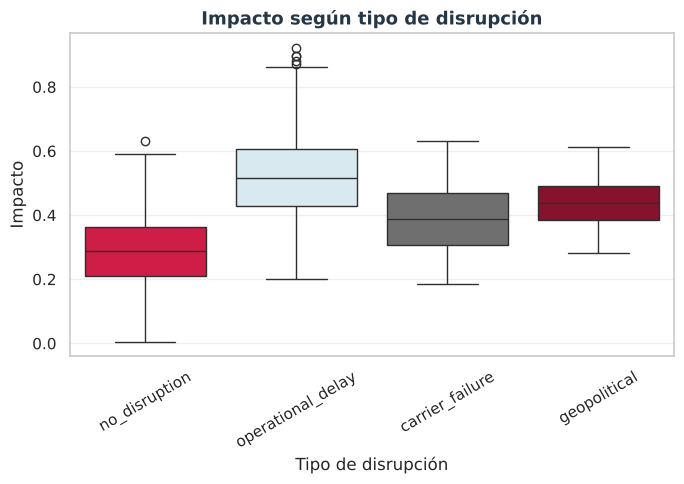

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

sns.boxplot(
    data=df,
    x="disruption_type",
    y="impact",
    hue="disruption_type",   # evita warning
    dodge=False,
    legend=False,
    palette=["#EB0037", "#D5EAF4", "#6F6F6F", "#990024"]
)

plt.title("Impacto según tipo de disrupción", fontsize=13, fontweight="bold")
plt.xlabel("Tipo de disrupción")
plt.ylabel("Impacto")

plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

El boxplot muestra una clara diferenciación en los niveles de impacto según el tipo de disrupción. Los retrasos operativos presentan la mayor mediana (0.52), seguidos de las disrupciones geopolíticas (0.44) y los fallos de transportista (0.39). Las filas sin factor extremo (`no_disruption`) tienen los valores más bajos (0.29). Este resultado confirma que el impacto del riesgo es heterogéneo y depende del tipo de evento.

## 5. ¿En cuáles rutas ocurren las mayores disrupciones?

In [37]:
# Crear ruta
df["route"] = df["origin_port"].astype(str) + " - " + df["destination_port"].astype(str)

# Top 10 rutas más disruptivas
rutas_mas_disrupcion = (
    df.groupby("route")["disruption_occurred"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
    .head(10)
)

# Extraer rutas
rutas_top = rutas_mas_disrupcion.index

#  Filtrar dataset
df_top = df[df["route"].isin(rutas_top)]

# EXCLUIR no_disruption
df_top = df_top[df_top["disruption_type"] != "no_disruption"]

# Tabla final
tabla_disrupciones = (
    df_top.groupby(["route", "disruption_type"])["disruption_occurred"]
    .mean()
    .round(2)
    .reset_index()
)

tabla_disrupciones

,route,disruption_type,disruption_occurred
0,busan - marseille,carrier_failure,1.00
1,busan - marseille,geopolitical,1.00
2,busan - marseille,operational_delay,1.00
3,busan - shanghai,carrier_failure,0.56
4,busan - shanghai,geopolitical,1.00
5,busan - shanghai,operational_delay,1.00
6,hamburg - los angeles,carrier_failure,0.67
7,hamburg - los angeles,geopolitical,0.89
8,hamburg - los angeles,operational_delay,1.00
9,hamburg - rotterdam,carrier_failure,0.71


### 5.1 P1. ¿Cuáles son las 10 rutas con mayor riesgo de Disrupción?

#### TOP 10 Rutas más disruptivas

In [38]:
tabla = (
    df_top.groupby(["route", "disruption_type"])
    .size()
    .reset_index(name="conteo")
)

tabla["proporcion"] = (
    tabla["conteo"] /
    tabla.groupby("route")["conteo"].transform("sum")
)

tabla_pivot = (
    tabla.pivot(index="route", columns="disruption_type", values="proporcion")
    .fillna(0)
)
tabla_pivot.round(2)

disruption_type,carrier_failure,geopolitical,operational_delay
route,,,
busan - marseille,0.06,0.19,0.75
busan - shanghai,0.38,0.21,0.42
hamburg - los angeles,0.24,0.36,0.40
hamburg - rotterdam,0.37,0.16,0.47
los angeles - singapore,0.29,0.33,0.38
rotterdam - busan,0.21,0.31,0.48
rotterdam - marseille,0.24,0.24,0.53
shanghai - marseille,0.13,0.30,0.57
shanghai - singapore,0.32,0.18,0.50


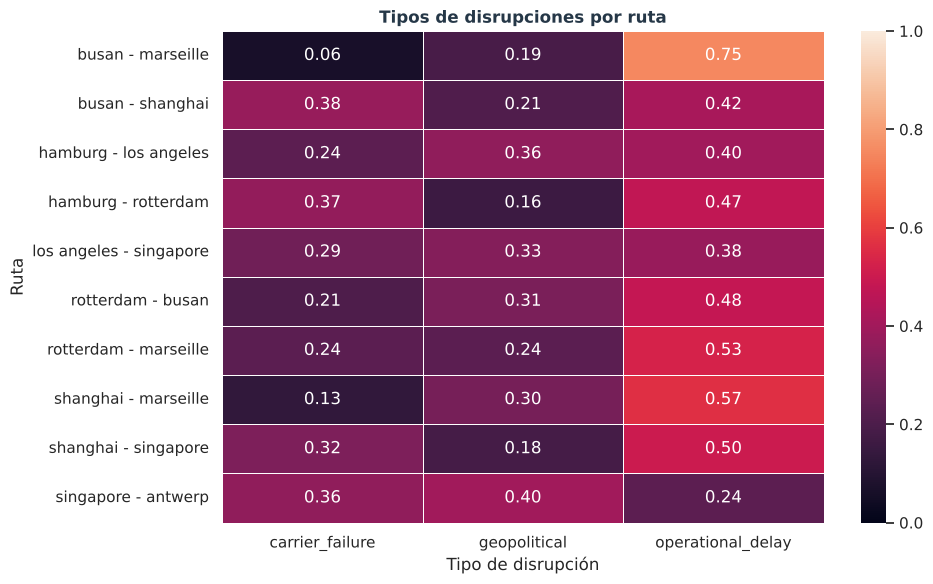

In [39]:
plt.figure(figsize=(10,6))

sns.heatmap(
    tabla_pivot,
    annot=True,        # muestra valores
    fmt=".2f",         # formato decimal
    
    linewidths=0.5,
    vmin=0,
    vmax=1
)

plt.title("Tipos de disrupciones por ruta")
plt.xlabel("Tipo de disrupción")
plt.ylabel("Ruta")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### 5.2 Rutas con mayor riesgo operativo


busan – marseille → 0.75


shanghai – marseille → 0.57


rotterdam – marseille → 0.53


shanghai – singapore → 0.50


rotterdam – busan → 0.48


hamburg – rotterdam → 0.47

**
**Conclusión: 
Estas rutas presentan una mayor exposición a retrasos operativos, cuellos de botella, congestión portuaria o ineficiencias en la ejecución logística.

### 5.3 Rutas con mayor riesgo geopolítico


singapore – antwerp → 0.40


hamburg – los angeles → 0.36


los angeles – singapore → 0.33


rotterdam – busan → 0.31


shanghai – marseille → 0.30


**Conclusión**
Estas rutas están más condicionadas por factores externos como tensiones internacionales, cambios regulatorios, restricciones comerciales o incertidumbre regional.

### 5.4 Rutas con mayor riesgo de carrier


busan – shanghai → 0.38


hamburg – rotterdam → 0.37


singapore – antwerp → 0.36


shanghai – singapore → 0.32


los angeles – singapore → 0.29


**Conclusión**
En estas rutas, el principal foco de riesgo está asociado al desempeño del operador logístico o transportista: fiabilidad, cumplimiento de SLA, capacidad y continuidad del servicio.

**Insight ejecutivo general**


Marsella aparece repetidamente en rutas con alto riesgo operativo.


Singapore / Antwerp concentra sensibilidad geopolítica y de carrier.


El riesgo no es homogéneo: cada corredor presenta drivers distintos, por lo que las estrategias de mitigación deben personalizarse por ruta.



El análisis muestra que cada ruta presenta un perfil de disrupción específico, donde predominan distintos tipos de riesgo (operativo, geopolítico o de carrier). Esto evidencia que la gestión del riesgo debe adaptarse a las características de cada ruta, en lugar de aplicar una estrategia uniforme

## 6. P2 P3 ¿Qué tan impactante es el riesgo? y ¿Dónde debo priorizar la inversión en mitigación?

Para responder esta pregunta se construyó un **índice de impacto compuesto** bajo la metodología ISO 31000, combinando tres dimensiones operativas: días de retraso, distancia de la ruta y peso del envío. Este índice permite comparar rutas en una escala normalizada (0–1) independientemente de su volumen de tráfico.

In [40]:
# ============================================
# IMPACTO + RIESGO — ISO 31000 
# ============================================

import pandas as pd
import numpy as np


# 1. VARIABLES BASE
if 'route' not in df.columns:
    df['route'] = df['origin_port'] + " - " + df['destination_port']

# 2. FILTRAR RUTAS DEL HEATMAP
rutas_top = tabla_pivot.index.tolist()
df_filtrado = df[df['route'].isin(rutas_top)].copy()

# 3. LIMPIEZA
df_filtrado['distance_km'] = df_filtrado['distance_km'].fillna(df_filtrado['distance_km'].median())
df_filtrado['weight_mt']   = df_filtrado['weight_mt'].fillna(df_filtrado['weight_mt'].median())

# 4. DELAY DAYS
if 'delay_days' not in df_filtrado.columns:
    df_filtrado['delay_days'] = (df_filtrado['lead_time_days'] - df_filtrado['lead_time_days'].median()).clip(lower=0)
df_filtrado['delay_days'] = df_filtrado['delay_days'].fillna(0)

# 5. IMPACTO (magnitud operativa: días de retraso × distancia × peso)
df_filtrado['impact_raw'] = (
    df_filtrado['delay_days'] *
    df_filtrado['distance_km'] *
    df_filtrado['weight_mt']
)

impact_min = df_filtrado['impact_raw'].min()
impact_max = df_filtrado['impact_raw'].max()
df_filtrado['impact_norm'] = 0 if impact_max == impact_min else (
    (df_filtrado['impact_raw'] - impact_min) / (impact_max - impact_min)
)

# ──────────────────────────────────────────────────────────────────────────────
# 6. PROBABILIDAD ' — usa disruption_occurred directamente
# ──────────────────────────────────────────────────────────────────────────────
df_filtrado['probability'] = df_filtrado.groupby('route')['disruption_occurred'].transform('mean')

print("Probabilidad por ruta (basada en disruption_occurred):")
print(df_filtrado.groupby('route')['probability'].first().sort_values(ascending=False).round(3))

# 7. CLASIFICACIÓN
df_filtrado['impact_level'] = pd.qcut(
    df_filtrado['impact_norm'].rank(method='first'),
    q=3, labels=['Low','Medium','High']
)
# La probabilidad es una propiedad de la ruta: se calculan terciles por ruta
# y se asignan a todas sus filas (antes se repartían filas, no rutas)
prob_ruta = df_filtrado.groupby('route')['probability'].first()
p_thr1, p_thr2 = prob_ruta.quantile([1/3, 2/3]).values

def nivel_prob(p):
    if p <= p_thr1:
        return 'Low'
    elif p <= p_thr2:
        return 'Medium'
    return 'High'

df_filtrado['prob_level'] = df_filtrado['probability'].map(nivel_prob)

# 8. MATRIZ ISO 31000
def risk_matrix(row):
    if row['impact_level'] == 'High' and row['prob_level'] == 'High':
        return 'Critical'
    elif row['impact_level'] == 'High' or row['prob_level'] == 'High':
        return 'High'
    elif row['impact_level'] == 'Medium' and row['prob_level'] == 'Medium':
        return 'Medium'
    else:
        return 'Low'

df_filtrado['risk_level_iso'] = df_filtrado.apply(risk_matrix, axis=1)

# 9. TRATAMIENTO
df_filtrado['tratamiento'] = np.select(
    [
        df_filtrado['risk_level_iso'] == 'Critical',
        df_filtrado['risk_level_iso'] == 'High',
        df_filtrado['risk_level_iso'] == 'Medium'
    ],
    ['Mitigación inmediata', 'Plan de contingencia', 'Monitoreo'],
    default='Aceptar'
)

# 10. TIPO DE RIESGO DOMINANTE
def tipo_riesgo(x):
    x = x[x != 'no_disruption']
    return x.value_counts().idxmax() if len(x) > 0 else 'no_disruption'

# 11. MATRIZ FINAL AGREGADA
df_risk_matrix = df_filtrado.groupby('route').agg(
    impact_norm     = ('impact_norm',    'mean'),
    probability     = ('probability',    'mean'),
    impact_level    = ('impact_level',   lambda x: x.mode()[0]),
    prob_level      = ('prob_level',     lambda x: x.mode()[0]),
    risk_level_iso  = ('risk_level_iso', lambda x: x.mode()[0]),
    tratamiento     = ('tratamiento',    lambda x: x.mode()[0]),
    disruption_type = ('disruption_type', tipo_riesgo)
).reset_index()

# 12. PRIORIZACIÓN
orden = {'Critical': 4, 'High': 3, 'Medium': 2, 'Low': 1}
df_risk_matrix['priority'] = df_risk_matrix['risk_level_iso'].map(orden)
df_risk_matrix = df_risk_matrix.sort_values(
    by=['priority','impact_norm'], ascending=False
).drop(columns='priority')

df_risk_matrix.round(3)


Probabilidad por ruta (basada en disruption_occurred):
route
rotterdam - marseille      0.750
los angeles - singapore    0.721
hamburg - rotterdam        0.708
rotterdam - busan          0.686
busan - shanghai           0.681
singapore - antwerp        0.681
shanghai - singapore       0.677
busan - marseille          0.677
hamburg - los angeles      0.671
shanghai - marseille       0.662
Name: probability, dtype: float64


,route,impact_norm,probability,impact_level,prob_level,risk_level_iso,tratamiento,disruption_type
5,rotterdam - busan,0.047,0.686,High,Medium,High,Plan de contingencia,operational_delay
6,rotterdam - marseille,0.041,0.750,Medium,High,High,Plan de contingencia,operational_delay
3,hamburg - rotterdam,0.039,0.708,High,High,High,Plan de contingencia,operational_delay
4,los angeles - singapore,0.028,0.721,Low,High,High,Plan de contingencia,operational_delay
1,busan - shanghai,0.033,0.681,Medium,Medium,Medium,Monitoreo,operational_delay
8,shanghai - singapore,0.057,0.677,Medium,Low,Low,Aceptar,operational_delay
7,shanghai - marseille,0.051,0.662,Low,Low,Low,Aceptar,operational_delay
0,busan - marseille,0.051,0.677,Low,Low,Low,Aceptar,operational_delay
2,hamburg - los angeles,0.045,0.671,High,Low,Low,Aceptar,operational_delay
9,singapore - antwerp,0.034,0.681,Low,Medium,Low,Aceptar,geopolitical


No todas las rutas son igual de peligrosas, y eso es precisamente lo que este análisis nos permite ver.
Para medir el riesgo no basta con saber si hubo una disrupción, sino entender cuánto daño causó. Por eso combinamos dos cosas: qué tan seguido ocurren problemas en una ruta, y qué tan grave es cuando ocurren, tomando en cuenta el tiempo de retraso, la distancia y el volumen del envío. Un retraso de tres días en una ruta corta no es lo mismo que ese mismo retraso en un envío intercontinental de gran tonelaje.
El resultado es claro: el riesgo está concentrado en pocas rutas. Hay rutas que acumulan alta frecuencia de problemas y alto impacto cuando fallan, esas son las críticas y las que necesitan atención inmediata. Otras tienen riesgo elevado pero más manejable, y el resto puede simplemente monitorearse.
Otro hallazgo importante es que el tipo de problema importa. Los retrasos operativos generan el mayor impacto medio (0.52), seguidos por los eventos geopolíticos, como cierres de fronteras o conflictos regionales (0.44), y por los fallos de transportista (0.39).
En definitiva, el riesgo en esta red logística no se distribuye de forma homogénea. Saber dónde se concentra y por qué permite tomar decisiones más inteligentes, en lugar de tratar todas las rutas por igual.
Las rutas con mayor riesgo están determinadas principalmente por la frecuencia de disrupciones, mientras que el impacto se mantiene en niveles moderados, lo que sugiere una estrategia enfocada en mitigación operativa más que en gestión de eventos extremos.

Capturando simultáneamente la severidad temporal, geográfica y operativa
de cada disrupción.

**3. Clasificación ISO 31000**
Combinando ambas dimensiones se asignó a cada ruta un nivel de riesgo:

| Nivel | Criterio | Acción |
|-------|----------|--------|
| 🔴 Critical | Alto impacto + Alta probabilidad | Mitigación inmediata |
| 🟠 High | Alto en una dimensión | Plan de contingencia |
| 🟡 Medium | Medio en ambas | Monitoreo |
| 🟢 Low | Bajo en ambas | Aceptar |

---

### 6.1 ¿Qué se encontró?

- **Todas las rutas superan el 65% de probabilidad** de disrupción, lo que
  indica una red logística con exposición generalizada al riesgo operativo.

- **Las rutas de mayor riesgo son de tipo operativo, y tres de las cuatro pasan por Rotterdam.** Rotterdam–Busan, Rotterdam–Marseille, Hamburg–Rotterdam y Los Ángeles–Singapore están en nivel High. Ninguna ruta alcanza nivel Critical.

- **Shanghai–Singapore tiene el mayor impacto normalizado del conjunto (0.057)**, pero su probabilidad está en el tercio bajo, por lo que queda en nivel Low y conviene vigilarla.

- **Singapore–Antwerp y Busan–Marseille** quedan en nivel Low, con impactos normalizados de 0.034 y 0.051.

- **La corrección del proxy de probabilidad** fue determinante: usar
  `disruption_occurred` en lugar de `delay_days > 0` produjo una clasificación
  de riesgo más precisa y alineada con la evidencia histórica real.

---

### 6.2 Estrategia de Monitoreo Recomendada

🔴 CRITICAL / HIGH → Mitigación inmediata: reevaluar carriers, aumentar buffers +15%

🟡 MEDIUM          → Monitoreo continuo con alertas automáticas

🟢 LOW             → Revisión trimestral, sin intervención urgente

---

### 6.3 Conclusión Final

El análisis demuestra que combinar **probabilidad histórica real** con un
**índice de impacto compuesto** permite una clasificación de riesgos más
robusta que los enfoques tradicionales basados en un solo indicador.

La visualización en matriz ISO, mapa interactivo y dashboard de monitoreo
transforma el análisis estático en una **herramienta de decisión dinámica**,
permitiendo priorizar recursos y anticipar disrupciones antes de que escalen.

> *"El riesgo no gestionado no desaparece — simplemente se vuelve más costoso."*

## 7. P5 ¿Qué acciones reducen el riesgo de forma inmediata?

In [41]:
import pandas as pd

# 1. MAPEAR TIPO DE RIESGO A ESPAÑOL
map_riesgo = {
    'operational_delay': 'Operativo',
    'geopolitical':      'Geopolítico',
    'carrier_failure':   'Carrier',
    'no_disruption':     'Sin disrupción'
}
df_risk_matrix['risk_type'] = df_risk_matrix['disruption_type'].map(map_riesgo)

# 2. DECISIONES EJECUTIVAS POR NIVEL + TIPO
def decision(row):
    nivel = row['risk_level_iso']
    tipo  = row['risk_type']

    if nivel == 'Critical':
        if tipo == 'Operativo':
            return 'Rediseñar red logística + buffer stock +20%'
        elif tipo == 'Geopolítico':
            return 'Eliminar ruta y diversificar geográficamente'
        else:
            return 'Reemplazar carrier inmediato'
    elif nivel == 'High':
        if tipo == 'Operativo':
            return 'Aumentar buffer +15% y ajustar planificación'
        elif tipo == 'Geopolítico':
            return 'Monitoreo semanal + activar rutas alternativas'
        else:
            return 'Reevaluar SLA del carrier; sustituir si fiabilidad < 85%'
    elif nivel == 'Medium':
        return 'Monitoreo continuo + alertas automáticas'
    else:
        return 'Revisión trimestral (riesgo aceptable)'

df_risk_matrix['decision'] = df_risk_matrix.apply(decision, axis=1)

# 3. PRIORIZACIÓN FINAL
orden = {'Critical': 4, 'High': 3, 'Medium': 2, 'Low': 1}
df_risk_matrix['priority'] = df_risk_matrix['risk_level_iso'].map(orden)
df_risk_matrix = df_risk_matrix.sort_values(
    by=['priority', 'impact_norm'], ascending=False
).drop(columns='priority')

# 4. MAPEO DE CONTINENTES
continente_map = {
    'rotterdam':   'Europa',
    'marseille':   'Europa',
    'hamburg':     'Europa',
    'antwerp':     'Europa',
    'busan':       'Asia',
    'shanghai':    'Asia',
    'singapore':   'Asia',
    'dubai':       'Asia',
    'los angeles': 'América',
}

df_risk_matrix[['origen', 'destino']] = (
    df_risk_matrix['route']
    .str.split(' - ', expand=True)
    .apply(lambda col: col.str.strip())
)

df_risk_matrix['continente_origen']  = df_risk_matrix['origen'].map(continente_map)
df_risk_matrix['continente_destino'] = df_risk_matrix['destino'].map(continente_map)

df_risk_matrix['ruta_continentes'] = (
    df_risk_matrix['continente_origen'] + ' → ' + df_risk_matrix['continente_destino']
)

# 5. OUTPUT EJECUTIVO
df_risk_matrix[['route', 'ruta_continentes', 'risk_level_iso', 'probability', 'risk_type', 'decision']].round(3)

df_risk_matrix.to_csv("df_risk_matrix.csv", index=False)

Las acciones están directamente alineadas con el nivel de riesgo y su causa principal, permitiendo decisiones específicas, medibles y priorizadas por ruta

In [42]:
import plotly.graph_objects as go
import pandas as pd

df_plot = df_risk_matrix.copy()

# ==================================================
# UMBRALES
# ==================================================
p1 = df_plot['probability'].quantile(1/3)
p2 = df_plot['probability'].quantile(2/3)
i1 = df_plot['impact_norm'].quantile(1/3)
i2 = df_plot['impact_norm'].quantile(2/3)

x_min = df_plot["probability"].min() - 0.01
x_max = df_plot["probability"].max() + 0.02
y_min = df_plot["impact_norm"].min() - 0.005
y_max = df_plot["impact_norm"].max() + 0.005

# ==================================================
# ICONOS REALES (mismos en gráfico y leyenda)
# ==================================================
ICON = {
    "carrier_failure": "🚛✈️🚢",
    "operational_delay": "⚙️",
    "geopolitical": "🌍",
    "no_disruption": "✓"
}

LABEL = {
    "carrier_failure": "Carrier failure",
    "operational_delay": "Operational delay",
    "geopolitical": "Geopolitical",
    "no_disruption": "No disruption"
}

fig = go.Figure()

# ==================================================
# FONDOS INTERMEDIOS
# ==================================================
zones = [
    (x_min,p1,y_min,i1,'#c8e6c9','Low'),
    (p1,p2,y_min,i1,'#dcedc8','Low'),
    (p2,x_max,y_min,i1,'#fff9c4','Medium'),

    (x_min,p1,i1,i2,'#c8e6c9','Low'),
    (p1,p2,i1,i2,'#fff59d','Medium'),
    (p2,x_max,i1,i2,'#ffcc80','High'),

    (x_min,p1,i2,y_max,'#fff9c4','Medium'),
    (p1,p2,i2,y_max,'#ffcc80','High'),
    (p2,x_max,i2,y_max,'#ef9a9a','Critical')
]

for x0,x1,y0,y1,color,label in zones:
    fig.add_shape(
        type="rect",
        x0=x0, x1=x1, y0=y0, y1=y1,
        fillcolor=color,
        opacity=0.78,
        line_width=0,
        layer="below"
    )

    fig.add_annotation(
        x=(x0+x1)/2,
        y=(y0+y1)/2,
        text=f"<b>{label}</b>",
        showarrow=False,
        font=dict(size=12, color="rgba(40,40,40,0.65)")
    )

# Líneas divisorias
for xv in [p1, p2]:
    fig.add_vline(x=xv, line_dash="dash", line_color="gray", opacity=0.55)

for yv in [i1, i2]:
    fig.add_hline(y=yv, line_dash="dash", line_color="gray", opacity=0.55)

# ==================================================
# ICONOS EN PUNTOS
# ==================================================
for _, row in df_plot.iterrows():
    tipo = row["disruption_type"]

    fig.add_trace(go.Scatter(
        x=[row["probability"]],
        y=[row["impact_norm"]],
        mode="text",
        text=[ICON[tipo]],
        textfont=dict(size=22),
        showlegend=False,
        hovertemplate=
            f"<b>{row['route']}</b><br>" +
            f"Tipo: {LABEL[tipo]}<br>" +
            f"Probabilidad: {row['probability']:.3f}<br>" +
            f"Impacto: {row['impact_norm']:.3f}<extra></extra>"
    ))

    fig.add_annotation(
        x=row["probability"],
        y=row["impact_norm"],
        text=row["route"],
        showarrow=False,
        yshift=24,
        font=dict(size=10, color="#253747"),
        bgcolor="rgba(255,255,255,0.92)"
    )

# ==================================================
# LEYENDA CON LOS MISMOS ICONOS
# ==================================================
# Ocultar leyenda nativa
fig.update_layout(showlegend=False)

# Caja blanca visible
fig.add_shape(
    type="rect",
    xref="paper", yref="paper",
    x0=0.78, x1=0.99,
    y0=0.70, y1=0.98,
    fillcolor="rgba(255,255,255,0.96)",
    line=dict(color="#D0D7DE", width=1),
    layer="above"
)

# Título
fig.add_annotation(
    x=0.885, y=0.955,
    xref="paper", yref="paper",
    text="<b>Tipo de disrupción</b>",
    showarrow=False,
    font=dict(size=13, color="#253747"),
    xanchor="center"
)

# Elementos
items = [
    ("🚛✈️🚢", "Carrier failure", 0.90),
    ("⚙️",     "Operational delay", 0.85),
    ("🌍",     "Geopolitical",      0.80),
    ("✓",      "No disruption",    0.75),
]

for icono, texto, y in items:
    fig.add_annotation(
        x=0.80, y=y,
        xref="paper", yref="paper",
        text=icono,
        showarrow=False,
        font=dict(size=16),
        xanchor="left"
    )

    fig.add_annotation(
        x=0.87, y=y,
        xref="paper", yref="paper",
        text=texto,
        showarrow=False,
        font=dict(size=12, color="#253747"),
        xanchor="left"
    )
# ==================================================
# LAYOUT
# ==================================================
fig.update_layout(
    title=dict(
        text="Matriz de Riesgo Operativo por Ruta · ISO 31000",
        x=0.5,
        font=dict(size=22, color="#253747")
    ),
    width=1450,
    height=820,
    plot_bgcolor="white",
    paper_bgcolor="white",
    legend_title="Tipo de disrupción",
    font=dict(size=12, color="#253747"),
    margin=dict(l=40, r=40, t=80, b=40)
)

fig.update_xaxes(
    title="Probabilidad de disrupción",
    range=[x_min, x_max],
    showgrid=False
)

fig.update_yaxes(
    title="Impacto normalizado",
    range=[y_min, y_max],
    showgrid=False
)

fig.show()
# 5. OUTPUT EJECUTIVO
df_risk_matrix[['route', 'ruta_continentes', 'risk_level_iso', 'probability', 'risk_type', 'decision']].round(3)

,route,ruta_continentes,risk_level_iso,probability,risk_type,decision
5,rotterdam - busan,Europa → Asia,High,0.686,Operativo,Aumentar buffer +15% y ajustar planificación
6,rotterdam - marseille,Europa → Europa,High,0.750,Operativo,Aumentar buffer +15% y ajustar planificación
3,hamburg - rotterdam,Europa → Europa,High,0.708,Operativo,Aumentar buffer +15% y ajustar planificación
4,los angeles - singapore,América → Asia,High,0.721,Operativo,Aumentar buffer +15% y ajustar planificación
1,busan - shanghai,Asia → Asia,Medium,0.681,Operativo,Monitoreo continuo + alertas automáticas
8,shanghai - singapore,Asia → Asia,Low,0.677,Operativo,Revisión trimestral (riesgo aceptable)
7,shanghai - marseille,Asia → Europa,Low,0.662,Operativo,Revisión trimestral (riesgo aceptable)
0,busan - marseille,Asia → Europa,Low,0.677,Operativo,Revisión trimestral (riesgo aceptable)
2,hamburg - los angeles,Europa → América,Low,0.671,Operativo,Revisión trimestral (riesgo aceptable)
9,singapore - antwerp,Asia → Europa,Low,0.681,Geopolítico,Revisión trimestral (riesgo aceptable)


Se utilizó impacto relativo porque las rutas tienen escalas muy diferentes. La normalización permite compararlas de forma homogénea y evitar sesgos por distancia o volumen.

El uso de impacto relativo permite una evaluación comparativa robusta, alineada con enfoques de priorización en gestión de riesgos bajo ISO 31000.

**IMPORTANTE**

Impacto absoluto → “cuánto duele en números reales”

Impacto relativo → “qué tan crítico es frente a otros”

### 7.1 Conclusión — Visualización Matriz de Riesgo ISO

El análisis de la matriz de riesgo ISO aplicada a las rutas logísticas marítimas permite
identificar de forma visual y estructurada el nivel de exposición operativa de cada ruta,
combinando la **probabilidad de ocurrencia** de disrupciones con su **impacto normalizado**.

---

#### Contexto
La mayoría de las rutas analizadas operan con probabilidades superiores a **0.65**,
lo que indica un entorno logístico de alta exposición al riesgo de manera generalizada.

---

#### Hallazgo Crítico
Ninguna ruta alcanza el nivel **Critical**. La ruta de mayor riesgo es **Rotterdam – Marseille**,
con la probabilidad más alta del conjunto (0.750) y nivel **High**.
> Es la prioridad número uno para implementar planes de contingencia inmediatos.

---

#### Hallazgos Secundarios
- **Rotterdam – Busan**, **Hamburg – Rotterdam** y **Los Ángeles – Singapore** también están en nivel High, con probabilidades entre 0.686 y 0.721.
- **Busan – Shanghai** está en riesgo medio (Medium).
- Por tipo de disrupción, los **retrasos operativos** (▲) tienen el mayor impacto medio (0.52), seguidos de los **geopolíticos** (◆) (0.44) y los **fallos de carrier** (0.39).

---

#### Rutas Estables
**Shanghai – Singapore**, **Shanghai – Marseille**, **Busan – Marseille**, **Hamburg – Los Ángeles** y **Singapore – Antwerp** quedan en nivel Low, con impactos normalizados entre 0.034 y 0.057. Shanghai – Singapore tiene el impacto más alto del grupo, así que conviene vigilarla aunque su nivel sea bajo.

---

#### Conclusión
Esta matriz demuestra que una gestión de riesgos **proactiva y diferenciada** por tipo
de disrupción es esencial para garantizar la resiliencia de la cadena logística,
priorizando las rutas de alto impacto antes de que escalen a nivel crítico.

In [43]:
"""
Dashboard de monitoreo de rutas logísticas (riesgo alto y medio).

Flujo general de la celda:
  1. Toma la tabla "df" que ya cargó el notebook (o el CSV si se ejecuta fuera de él)
     y calcula, por ruta, probabilidad, impacto y nivel de riesgo ISO 31000.
  2. Genera un HTML autocontenido con KPIs, filtros, matriz de riesgo, mapa mundi y tabla
     de decisiones. Los filtros recalculan todo en el navegador (JavaScript).
  3. Guarda el archivo "index.html" y lo abre en el navegador (no bloquea el notebook).

Requisitos:
    pip install pandas numpy plotly
Mapa del mundo (archivo land.json, en la misma carpeta del notebook):
    npm install world-atlas topojson-client
    node make_land.js
"""
# Librerías de la biblioteca estándar: codificación, HTML, JSON, matemáticas,
# sistema de archivos, servidor web local y apertura del navegador.
import base64
import html
import json
import math
import os
import pathlib
import webbrowser

# Librerías de datos y gráficos.
import numpy as np
import pandas as pd
import plotly

# ---------- CONFIGURACIÓN ----------
# Rutas de archivos de entrada y salida.
# Los colores siguen la escala de riesgo: rojo (crítico), naranja (alto),
# amarillo (medio) y verde (bajo).
CSV_PATH = "global_supply_chain_risk_2026.csv"
LAND_PATH = "land.json"
OUTPUT_PATH = "index.html"

COLORES = {"Critical": "#ff4d6d", "High": "#ff9f1c", "Medium": "#ffd60a", "Low": "#2ee59d"}
ACENTO = "#5ce1e6"
ORDEN = {"Critical": 4, "High": 3, "Medium": 2, "Low": 1}
COORDS = {  # (lat, lon)
    "rotterdam": (51.9244, 4.4777), "busan": (35.1796, 129.0756),
    "marseille": (43.2965, 5.3698), "hamburg": (53.5753, 10.0153),
    "shanghai": (31.2304, 121.4737), "los angeles": (33.9425, -118.4081),
    "singapore": (1.3521, 103.8198), "antwerp": (51.2194, 4.4025),
    "dubai": (25.2048, 55.2708),
}
POS_TEXTO = {"rotterdam": "bottom center", "antwerp": "bottom left", "hamburg": "top right"}
TIPO = {"operational_delay": "Operativo", "geopolitical": "Geopolítico",
        "carrier_failure": "Carrier", "no_disruption": "Sin disrupción"}

# ---------- 1. DATOS ----------
# Usa la tabla "df" que ya cargó el notebook (sin modificarla). Si la celda se ejecuta
# fuera del notebook, lee el CSV. Todo el trabajo se hace sobre la copia "datos".
try:
    datos = df.copy()
except NameError:
    datos = pd.read_csv(CSV_PATH)

# Normaliza nombres de columnas (minúsculas, sin espacios) y valida que existan las necesarias.
datos.columns = datos.columns.str.strip().str.lower()
COLUMNAS_REQUERIDAS = [
    "origin_port", "destination_port", "geopolitical_risk_score", "carrier_reliability_score",
    "lead_time_days", "distance_km", "weight_mt", "disruption_occurred",
]
faltan = [c for c in COLUMNAS_REQUERIDAS if c not in datos.columns]
if faltan:
    raise KeyError(f"Faltan columnas para el dashboard: {faltan}")

for c in ["origin_port", "destination_port"]:
    datos[c] = datos[c].astype(str).str.strip().str.lower()
# Cada ruta es un par origen–destino, por ejemplo "rotterdam - marseille".
datos["route"] = datos["origin_port"] + " - " + datos["destination_port"]

# Umbrales extremos (percentiles) para clasificar el tipo de disrupción de cada envío.
p90_geo = datos["geopolitical_risk_score"].quantile(0.90)
p10_rel = datos["carrier_reliability_score"].quantile(0.10)
p90_delay = datos["lead_time_days"].quantile(0.90)


def clasificar(r):
    """Devuelve el factor más extremo del envío (geopolítico, carrier u operativo)."""
    s = {}
    if r["geopolitical_risk_score"] > p90_geo:
        s["geopolitical"] = (r["geopolitical_risk_score"] - p90_geo) / p90_geo
    if r["carrier_reliability_score"] < p10_rel:
        s["carrier_failure"] = (p10_rel - r["carrier_reliability_score"]) / p10_rel
    if r["lead_time_days"] > p90_delay:
        s["operational_delay"] = (r["lead_time_days"] - p90_delay) / p90_delay
    return max(s, key=s.get) if s else "no_disruption"


datos["disruption_type"] = datos.apply(clasificar, axis=1)

# Las 10 rutas con mayor tasa de disrupción. Solo se evalúan estas.
top = datos.groupby("route")["disruption_occurred"].mean().sort_values(ascending=False).head(10).index
# Envíos de las 10 rutas seleccionadas. Se rellenan valores faltantes con la mediana
# y se calcula el impacto: retraso × distancia × peso, normalizado entre 0 y 1.
f = datos[datos["route"].isin(top)].copy()
f["distance_km"] = f["distance_km"].fillna(f["distance_km"].median())
f["weight_mt"] = f["weight_mt"].fillna(f["weight_mt"].median())
f["delay_days"] = (f["lead_time_days"] - f["lead_time_days"].median()).clip(lower=0).fillna(0)
raw = f["delay_days"] * f["distance_km"] * f["weight_mt"]
f["impact_norm"] = (raw - raw.min()) / (raw.max() - raw.min())
f["probability"] = f.groupby("route")["disruption_occurred"].transform("mean")


def tipo_dominante(x):
    """Tipo de disrupción más frecuente de una ruta (ignorando "sin disrupción")."""
    x = x[x != "no_disruption"]
    return x.value_counts().idxmax() if len(x) else "no_disruption"


m = f.groupby("route").agg(
    probability=("probability", "mean"),
    impact_norm=("impact_norm", "mean"),
    distancia_km=("distance_km", "mean"),
    envios=("route", "size"),
    tipo=("disruption_type", tipo_dominante),
).reset_index()


# DECISIÓN DE DISEÑO: los terciles se calculan sobre las RUTAS (promedio por ruta),
# no sobre cada envío. Así la matriz, la tabla y el mapa usan los mismos niveles.
def tercil(s):
    """Clasifica cada valor en Low, Medium o High según los terciles de la serie."""
    q1, q2 = s.quantile([1 / 3, 2 / 3])
    return np.where(s <= q1, "Low", np.where(s <= q2, "Medium", "High"))


m["impact_level"] = tercil(m["impact_norm"])
m["prob_level"] = tercil(m["probability"])


def nivel(r):
    """Nivel ISO 31000 combinando impacto y probabilidad (matriz 3×3)."""
    if r["impact_level"] == "High" and r["prob_level"] == "High":
        return "Critical"
    if r["impact_level"] == "High" or r["prob_level"] == "High":
        return "High"
    if r["impact_level"] == "Medium" and r["prob_level"] == "Medium":
        return "Medium"
    return "Low"


def accion(row):
    """Acción recomendada según el nivel y el tipo de disrupción de la ruta."""
    n, t = row["nivel"], row["tipo"]
    if n == "Critical":
        if t == "operational_delay":
            return "Rediseñar red logística + buffer stock +20%"
        if t == "geopolitical":
            return "Eliminar ruta y diversificar geográficamente"
        return "Reemplazar carrier inmediato"
    if n == "High":
        if t == "operational_delay":
            return "Aumentar buffer +15% y ajustar planificación"
        if t == "geopolitical":
            return "Monitoreo semanal + activar rutas alternativas"
        return "Reevaluar SLA del carrier; sustituir si fiabilidad < 85%"
    if n == "Medium":
        return "Monitoreo continuo + alertas automáticas"
    return "Revisión trimestral (riesgo aceptable)"


m["nivel"] = m.apply(nivel, axis=1)
m["accion"] = m.apply(accion, axis=1)
m["origen"] = m["route"].str.split(" - ").str[0]
m["destino"] = m["route"].str.split(" - ").str[1]
n_rutas = len(m)

# ---------- ICONOS DE DISRUPCIÓN (SVG embebido) ----------
# Cada tipo de disrupción tiene un símbolo SVG. Va incrustado en el HTML (data URI),
# así que la página no necesita archivos de imagen externos.
ETIQUETA_TIPO = {"carrier_failure": "Fallo de carrier", "operational_delay": "Retraso operativo",
                 "geopolitical": "Geopolítico", "no_disruption": "Sin disrupción"}
GLIFOS = {
    "operational_delay": ('<circle cx="32" cy="32" r="14" fill="none" stroke="FG" stroke-width="7" '
                          'stroke-dasharray="5.2 4.4"/><circle cx="32" cy="32" r="8" fill="none" '
                          'stroke="FG" stroke-width="3.5"/>'),
    "geopolitical": ('<circle cx="32" cy="32" r="16" fill="none" stroke="FG" stroke-width="3.5"/>'
                     '<ellipse cx="32" cy="32" rx="7" ry="16" fill="none" stroke="FG" stroke-width="3"/>'
                     '<line x1="16" y1="32" x2="48" y2="32" stroke="FG" stroke-width="3"/>'),
    "carrier_failure": ('<rect x="10" y="22" width="26" height="18" rx="2" fill="FG"/>'
                        '<path d="M38 28 h10 l7 7 v5 h-17z" fill="FG"/>'
                        '<circle cx="20" cy="43" r="5" fill="FG" stroke="#061223" stroke-width="2"/>'
                        '<circle cx="44" cy="43" r="5" fill="FG" stroke="#061223" stroke-width="2"/>'),
    "no_disruption": ('<polyline points="16,34 27,45 48,22" fill="none" stroke="FG" stroke-width="6" '
                      'stroke-linecap="round" stroke-linejoin="round"/>'),
}


def icono_uri(tipo, color):
    """Devuelve el símbolo del tipo indicado pintado con el color dado, como data URI."""
    glifo = GLIFOS.get(tipo, GLIFOS["no_disruption"]).replace("FG", color)
    svg = (f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 64 64">'
           f'<defs><filter id="g" x="-30%" y="-30%" width="160%" height="160%">'
           f'<feDropShadow dx="0" dy="0" stdDeviation="2" flood-color="{color}" flood-opacity="0.9"/>'
           f'</filter></defs><g filter="url(#g)">{glifo}</g></svg>')
    return "data:image/svg+xml;base64," + base64.b64encode(svg.encode("utf-8")).decode("ascii")

# ---------- 2. DATOS PARA EL DASHBOARD INTERACTIVO ----------
# Umbrales de la matriz (terciles) y los datos de cada ruta, que se pasan a JavaScript.
p1, p2 = m["probability"].quantile([1 / 3, 2 / 3])
i1, i2 = m["impact_norm"].quantile([1 / 3, 2 / 3])
XB = [float(m["probability"].min() - 0.01), float(p1), float(p2), float(m["probability"].max() + 0.02)]
YB = [float(m["impact_norm"].min() - 0.005), float(i1), float(i2), float(m["impact_norm"].max() + 0.005)]

# Contornos de los continentes (generados con make_land.js) para dibujar el mapa.
if not pathlib.Path(LAND_PATH).exists():
    raise FileNotFoundError(
        f"No encuentro '{LAND_PATH}'. Colócalo en la misma carpeta del notebook "
        "(se genera con make_land.js)."
    )
with open(LAND_PATH, encoding="utf-8") as fh:
    LAND = json.load(fh)


def arco(la1, lo1, la2, lo2, n=60):
    """Arco de círculo máximo entre dos ciudades; corta la línea en el antimeridiano."""
    p1r, l1, p2r, l2 = map(math.radians, [la1, lo1, la2, lo2])
    d = 2 * math.asin(math.sqrt(math.sin((p2r - p1r) / 2) ** 2 +
                                math.cos(p1r) * math.cos(p2r) * math.sin((l2 - l1) / 2) ** 2))
    xs, ys = [], []
    for i in range(n + 1):
        t = i / n
        a = math.sin((1 - t) * d) / math.sin(d)
        b = math.sin(t * d) / math.sin(d)
        x = a * math.cos(p1r) * math.cos(l1) + b * math.cos(p2r) * math.cos(l2)
        y = a * math.cos(p1r) * math.sin(l1) + b * math.cos(p2r) * math.sin(l2)
        z = a * math.sin(p1r) + b * math.sin(p2r)
        lat = math.degrees(math.atan2(z, math.hypot(x, y)))
        lon = math.degrees(math.atan2(y, x))
        if xs and abs(lon - xs[-1]) > 180:
            xs.append(None)
            ys.append(None)
        xs.append(round(lon, 3))
        ys.append(round(lat, 3))
    return xs, ys


# Símbolos precalculados por combinación de tipo y nivel.
ICONOS = {t: {n: icono_uri(t, COLORES[n]) for n in COLORES} for t in ETIQUETA_TIPO}

# Lista de rutas con todo lo que necesita la página (se serializa a JSON).
rutas = []
for _, r in m.iterrows():
    (la1, lo1), (la2, lo2) = COORDS[r["origen"]], COORDS[r["destino"]]
    xs, ys = arco(la1, lo1, la2, lo2)
    rutas.append({
        "ruta": r["route"].title(), "origen": r["origen"], "destino": r["destino"],
        "nivel": r["nivel"], "tipo": r["tipo"], "tipo_etq": ETIQUETA_TIPO.get(r["tipo"], r["tipo"]),
        "prob": round(float(r["probability"]), 3), "imp": round(float(r["impact_norm"]), 4),
        "accion": r["accion"], "arco_x": xs, "arco_y": ys,
        "icono": ICONOS[r["tipo"]][r["nivel"]],
        "dist": round(float(r["distancia_km"]), 1), "envios": int(r["envios"]),
    })

# Datos que el JavaScript de la página usa para filtrar y dibujar. "ensure_ascii=False"
# conserva las tildes.
DATOS_JSON = json.dumps({
    "rutas": rutas, "land": LAND, "xb": XB, "yb": YB, "colores": COLORES,
    "etiquetas": ETIQUETA_TIPO, "coords": {c: [v[1], v[0]] for c, v in COORDS.items()},
}, ensure_ascii=False)

n_rutas = len(m)
n_alto = int(m["nivel"].isin(["Critical", "High"]).sum())
n_medio = int((m["nivel"] == "Medium").sum())
prob_prom = m["probability"].mean()
imp_prom = m["impact_norm"].mean()
pct_disrup = f["disruption_occurred"].mean()
envios = int(m["envios"].sum())
mediana_dist = m["distancia_km"].median()


def card(titulo, valor, sub, color, id_):
    """Tarjeta KPI con identificadores para que JavaScript pueda actualizar sus valores."""
    return (f'<div class="kpi"><div class="kpi-t">{titulo}</div>'
            f'<div class="kpi-v" id="{id_}-v" style="color:{color}">{valor}</div>'
            f'<div class="kpi-s" id="{id_}-s">{sub}</div></div>')


# Tarjetas de KPI. Sus valores se recalculan en el navegador al cambiar los filtros.
KPIS_HTML = "".join([
    card("Rutas evaluadas", n_rutas, f"{envios:,} envíos analizados", "#5ce1e6", "k-rutas"),
    card("Riesgo alto o crítico", n_alto, f"de {n_rutas} rutas", COLORES["High"], "k-alto"),
    card("Riesgo medio", n_medio, f"de {n_rutas} rutas", COLORES["Medium"], "k-medio"),
    card("Probabilidad promedio", f"{prob_prom:.2f}", f"{pct_disrup:.0%} de envíos con disrupción", "#5ce1e6", "k-prob"),
    card("Impacto promedio", f"{imp_prom:.3f}", "índice normalizado 0–1", "#5ce1e6", "k-imp"),
    card("Distancia mediana", f"{mediana_dist:,.0f} km", "de las rutas filtradas", "#5ce1e6", "k-dist"),
])

# Leyenda con los símbolos de cada tipo de disrupción.
LEYENDA_ICONOS = " &nbsp; ".join(
    f'<img src="{icono_uri(t, "#5ce1e6")}" width="20" height="20" style="vertical-align:middle"> {etq}'
    for t, etq in ETIQUETA_TIPO.items())

# Opciones del filtro de tipo de disrupción.
OPC_TIPO = "".join(f'<option value="{t}">{etq}</option>' for t, etq in ETIQUETA_TIPO.items())

# ---------- 3. PÁGINA INTERACTIVA ----------
# Plantilla HTML con CSS y JavaScript. Es una cadena "raw" (r"""...""") para que las
# expresiones regulares de JavaScript (como \b) no se interpreten como escapes de Python.
# En la plantilla, los marcadores __NOMBRE__ se reemplazan más abajo.
PLANTILLA = r"""<!doctype html>
<html lang="es"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Rutas de riesgo</title>
<style>
  body { margin:0; background:radial-gradient(circle at 50% -10%, #12395f 0%, #061223 60%);
         font-family:"Segoe UI", Arial, sans-serif; color:#e6f1ff; min-height:100vh; }
  header { background:rgba(8,26,46,.85); border-bottom:1px solid #1d4a6b; padding:22px 32px; }
  header h1 { margin:0; font-size:24px; font-weight:600; }
  header p { margin:6px 0 0; font-size:13px; color:#7fa8c4; }
  main { padding:24px 32px; max-width:1400px; margin:auto; }
  h2 { font-size:14px; margin:26px 0 12px; font-weight:600; color:#5ce1e6; text-transform:uppercase; letter-spacing:.08em; }
  .kpis { display:grid; grid-template-columns:repeat(auto-fit, minmax(170px,1fr)); gap:14px; }
  .kpi { background:rgba(12,38,64,.75); border:1px solid #1d4a6b; border-radius:10px; padding:16px 18px; text-align:center; }
  .kpi-t { font-size:12px; color:#7fa8c4; text-transform:uppercase; letter-spacing:.04em; }
  .kpi-v { font-size:30px; font-weight:700; margin:6px 0 2px; }
  .kpi-s { font-size:12px; color:#7fa8c4; }
  .filtros { display:flex; flex-wrap:wrap; gap:16px; align-items:center; margin:18px 0 0; font-size:13px; color:#7fa8c4; }
  select { background:#0c2640; color:#e6f1ff; border:1px solid #1d4a6b; border-radius:6px; padding:7px 10px; font-size:13px; }
  #conteo { margin-left:auto; color:#5ce1e6; font-weight:600; }
  .dos { display:grid; grid-template-columns:1fr 1fr; gap:14px; align-items:stretch; }
  @media (max-width: 960px) { .dos { grid-template-columns:1fr; } }
  .card { background:rgba(12,38,64,.75); border:1px solid #1d4a6b; border-radius:10px; padding:14px; }
  .leyenda { font-size:12px; color:#7fa8c4; margin:6px 0 0; }
  .dot { display:inline-block; width:10px; height:10px; border-radius:50%; margin:0 4px 0 12px; vertical-align:middle; }
  table { width:100%; border-collapse:collapse; font-size:14px; }
  th { text-align:left; font-size:12px; color:#7fa8c4; text-transform:uppercase; letter-spacing:.04em;
       padding:10px 12px; border-bottom:1px solid #1d4a6b; }
  td { padding:11px 12px; border-bottom:1px solid #15385a; vertical-align:middle; color:#e6f1ff; }
  td.num { text-align:right; font-variant-numeric:tabular-nums; }
  .pill { color:#061223; font-size:12px; font-weight:600; padding:3px 10px; border-radius:12px; }
  .vacio { color:#7fa8c4; text-align:center; padding:24px; }
</style></head>
<body>
<header>
  <h1>Rutas de riesgo</h1>
  <p>Clasificación ISO 31000 · fuente: __CSV__</p>
</header>
<main>
  <h2>Indicadores clave</h2>
  <div class="kpis">__KPIS__</div>

  <div class="dos">
    <div>
      <h2>Matriz de riesgo ISO 31000</h2>
      <div class="card">
        <div id="matriz"></div>
        <p class="leyenda">Zonas según terciles de probabilidad e impacto sobre las 10 rutas.<br>__LEYENDA__</p>
      </div>
    </div>
    <div>
      <h2>Mapa de rutas</h2>
      <div class="card">
        <div id="mapa"></div>
        <p class="leyenda">
          <span class="dot" style="background:__C_CRIT__"></span>Crítico
          <span class="dot" style="background:__C_HIGH__"></span>Alto
          <span class="dot" style="background:__C_MED__"></span>Medio
          <span class="dot" style="background:__C_LOW__"></span>Bajo.
          Pasa el cursor sobre una ruta para ver su decisión.</p>
      </div>
      <div class="card" style="margin-top:14px">
        <div class="filtros">
    <label>Nivel de riesgo
      <select id="fNivel">
        <option value="AH" selected>Alto y medio</option>
        <option value="todos">Todos los niveles</option>
        <option value="Critical">Crítico</option>
        <option value="High">Alto</option>
        <option value="Medium">Medio</option>
        <option value="Low">Bajo</option>
      </select>
    </label>
    <label>Tipo de disrupción
      <select id="fTipo"><option value="todos">Todos</option>__OPC_TIPO__</select>
    </label>
    <span id="conteo"></span>
  </div>
      </div>
    </div>
  </div>

  <h2>Decisiones por ruta</h2>
  <div class="card">
    <table>
      <thead><tr><th>Nivel</th><th>Ruta</th><th>Tipo</th><th style="text-align:right">Probabilidad</th>
        <th style="text-align:right">Impacto</th><th>Decisión</th></tr></thead>
      <tbody id="tabla"></tbody>
    </table>
  </div>
</main>

<script>__PLOTLY__</script>
<script>
const D = __DATOS__;
const CFG = {displayModeBar: false, responsive: true};
const FONT = {family: 'Segoe UI, Arial, sans-serif', color: '#cfe8f5'};

function filtrar() {
  const n = document.getElementById('fNivel').value;
  const t = document.getElementById('fTipo').value;
  return D.rutas.filter(r => {
    const okNivel = n === 'todos' ? true
      : n === 'AH' ? ['Critical', 'High', 'Medium'].includes(r.nivel)
      : r.nivel === n;
    const okTipo = t === 'todos' || r.tipo === t;
    return okNivel && okTipo;
  });
}

function nivelCelda(pl, il) {
  if (il === 'High' && pl === 'High') return 'Critical';
  if (il === 'High' || pl === 'High') return 'High';
  if (il === 'Medium' && pl === 'Medium') return 'Medium';
  return 'Low';
}

function rgba(hex, a) {
  const h = hex.replace('#', '');
  return `rgba(${parseInt(h.slice(0,2),16)},${parseInt(h.slice(2,4),16)},${parseInt(h.slice(4,6),16)},${a})`;
}

function dibujarMatriz(lista) {
  const [x0, x1, x2, x3] = D.xb, [y0, y1, y2, y3] = D.yb;
  const xs = [x0, x1, x2, x3], ys = [y0, y1, y2, y3];
  const niveles = ['Low', 'Medium', 'High'];
  const shapes = [], anotaciones = [];
  for (let i = 0; i < 3; i++) {
    for (let j = 0; j < 3; j++) {
      const nv = nivelCelda(niveles[j], niveles[i]);
      shapes.push({type: 'rect', x0: xs[j], x1: xs[j+1], y0: ys[i], y1: ys[i+1],
                   fillcolor: rgba(D.colores[nv], 0.22), line: {width: 0}, layer: 'below'});
      anotaciones.push({x: (xs[j] + xs[j+1]) / 2, y: (ys[i] + ys[i+1]) / 2, text: nv,
                        showarrow: false, font: {size: 12, color: '#7fa8c4'}});
    }
  }
  const W = x3 - x0, H = y3 - y0;
  const imagenes = lista.map(r => ({source: r.icono, xref: 'x', yref: 'y', x: r.prob, y: r.imp,
                                    sizex: 34 * W / 620, sizey: 34 * H / 360,
                                    xanchor: 'center', yanchor: 'middle', layer: 'above'}));
  const traza = {type: 'scatter', mode: 'markers+text', x: lista.map(r => r.prob), y: lista.map(r => r.imp),
    text: lista.map(r => r.ruta), textposition: 'top center', textfont: {size: 9, color: '#cfe8f5'},
    marker: {size: 38, color: 'rgba(0,0,0,0)'},
    customdata: lista.map(r => [r.nivel, r.tipo_etq, r.accion]),
    hovertemplate: '<b>%{text}</b><br>Probabilidad: %{x:.2f}<br>Impacto: %{y:.3f}<br>Nivel: %{customdata[0]}<br>Tipo: %{customdata[1]}<br>Decisión: %{customdata[2]}<extra></extra>',
    showlegend: false};
  const layout = {height: 430, margin: {l: 62, r: 14, t: 12, b: 56}, paper_bgcolor: '#081a2e',
    plot_bgcolor: '#081a2e', font: FONT, shapes, annotations: anotaciones, images: imagenes,
    xaxis: {title: {text: 'Probabilidad de disrupción', font: {color: '#7fa8c4'}}, range: [x0, x3],
            showgrid: false, zeroline: false, tickfont: {color: '#7fa8c4'}},
    yaxis: {title: {text: 'Impacto normalizado', font: {color: '#7fa8c4'}}, range: [y0, y3],
            showgrid: false, zeroline: false, tickfont: {color: '#7fa8c4'}}};
  Plotly.react('matriz', [traza], layout, CFG);
}

function dibujarMapa(lista) {
  const tierra = {type: 'scatter', mode: 'lines', fill: 'toself', fillcolor: '#12304f',
    line: {width: 0.6, color: '#24557f'}, hoverinfo: 'skip', showlegend: false,
    x: [], y: []};
  D.land.forEach(a => { tierra.x.push(...a.map(p => p[0]), null); tierra.y.push(...a.map(p => p[1]), null); });
  const trazas = [tierra];
  lista.forEach(r => {
    const texto = `<b>${r.ruta.replace(/\b\w/g, c => c.toUpperCase())}</b><br>Nivel: ${r.nivel}<br>` +
                  `Probabilidad: ${r.prob.toFixed(2)} · Impacto: ${r.imp.toFixed(3)}<br>Decisión: ${r.accion}`;
    trazas.push({type: 'scatter', mode: 'lines', x: r.arco_x, y: r.arco_y, opacity: 0.18,
                 line: {width: 5, color: D.colores[r.nivel]}, hoverinfo: 'skip', showlegend: false});
    trazas.push({type: 'scatter', mode: 'lines', x: r.arco_x, y: r.arco_y,
                 line: {width: 1.3, color: D.colores[r.nivel]}, hoverinfo: 'text', text: texto, showlegend: false});
  });
  const ciudades = [...new Set(lista.flatMap(r => [r.origen, r.destino]))].sort();
  trazas.push({type: 'scatter', mode: 'markers+text', x: ciudades.map(c => D.coords[c][0]),
    y: ciudades.map(c => D.coords[c][1]), text: ciudades.map(c => c.replace(/\b\w/g, s => s.toUpperCase())),
    textposition: ciudades.map(c => ({rotterdam: 'bottom center', antwerp: 'bottom left', hamburg: 'top right'})[c] || 'top center'),
    textfont: {size: 10, color: '#cfe8f5'}, marker: {size: 6, color: '#5ce1e6'}, hoverinfo: 'skip', showlegend: false});
  const layout = {height: 340, margin: {l: 0, r: 0, t: 0, b: 0}, paper_bgcolor: '#081a2e',
    plot_bgcolor: '#081a2e', font: FONT,
    xaxis: {range: [-150, 150], showgrid: false, zeroline: false, showticklabels: false, fixedrange: true},
    yaxis: {range: [-58, 78], showgrid: false, zeroline: false, showticklabels: false, fixedrange: true}};
  Plotly.react('mapa', trazas, layout, CFG);
}

function dibujarTabla(lista) {
  const orden = {Critical: 4, High: 3, Medium: 2, Low: 1};
  const filas = [...lista].sort((a, b) => orden[b.nivel] - orden[a.nivel] || b.imp - a.imp);
  const tb = document.getElementById('tabla');
  if (!filas.length) { tb.innerHTML = '<tr><td class="vacio" colspan="6">No hay rutas con este filtro</td></tr>'; return; }
  tb.innerHTML = filas.map(r =>
    `<tr><td><span class="pill" style="background:${D.colores[r.nivel]}">${r.nivel}</span></td>` +
    `<td>${r.ruta}</td><td>${r.tipo_etq}</td>` +
    `<td class="num">${r.prob.toFixed(2)}</td><td class="num">${r.imp.toFixed(3)}</td>` +
    `<td>${r.accion}</td></tr>`).join('');
}

function mediana(v) {
  const s = [...v].sort((a, b) => a - b), k = s.length;
  if (!k) return 0;
  return k % 2 ? s[(k - 1) / 2] : (s[k / 2 - 1] + s[k / 2]) / 2;
}

function fijar(id, texto) { document.getElementById(id).textContent = texto; }

function miles(n) { return String(Math.round(n)).replace(/\B(?=(\d{3})+(?!\d))/g, '.'); }

function actualizarKpis(l) {
  const N = l.length;
  const env = l.reduce((s, r) => s + r.envios, 0);
  const alto = l.filter(r => r.nivel === 'Critical' || r.nivel === 'High').length;
  const medio = l.filter(r => r.nivel === 'Medium').length;
  const prob = N ? l.reduce((s, r) => s + r.prob, 0) / N : 0;
  const pct = env ? l.reduce((s, r) => s + r.prob * r.envios, 0) / env : 0;
  const imp = N ? l.reduce((s, r) => s + r.imp, 0) / N : 0;
  fijar('k-rutas-v', N);
  fijar('k-rutas-s', `${miles(env)} envíos analizados`);
  fijar('k-alto-v', alto);
  fijar('k-alto-s', `de ${N} rutas`);
  fijar('k-medio-v', medio);
  fijar('k-medio-s', `de ${N} rutas`);
  fijar('k-prob-v', prob.toFixed(2));
  fijar('k-prob-s', `${Math.round(pct * 100)}% de envíos con disrupción`);
  fijar('k-imp-v', imp.toFixed(3));
  fijar('k-dist-v', miles(mediana(l.map(r => r.dist))) + ' km');
}

function actualizar() {
  const lista = filtrar();
  actualizarKpis(lista);
  document.getElementById('conteo').textContent = `${lista.length} de ${D.rutas.length} rutas`;
  dibujarMatriz(lista);
  dibujarMapa(lista);
  dibujarTabla(lista);
}

document.getElementById('fNivel').addEventListener('change', actualizar);
document.getElementById('fTipo').addEventListener('change', actualizar);
actualizar();
</script>
</body></html>
"""

# Reemplaza los marcadores de la plantilla por los valores calculados.
# La librería de Plotly se incrusta completa para que la página funcione sin internet.
pagina = (PLANTILLA
          .replace("__CSV__", html.escape(CSV_PATH))
          .replace("__KPIS__", KPIS_HTML)
          .replace("__OPC_TIPO__", OPC_TIPO)
          .replace("__LEYENDA__", LEYENDA_ICONOS)
          .replace("__C_CRIT__", COLORES["Critical"]).replace("__C_HIGH__", COLORES["High"])
          .replace("__C_MED__", COLORES["Medium"]).replace("__C_LOW__", COLORES["Low"])
          .replace("__PLOTLY__", plotly.offline.get_plotlyjs())
          .replace("__DATOS__", DATOS_JSON))

with open(OUTPUT_PATH, "w", encoding="utf-8") as fh:
    fh.write(pagina)
print(f"Rutas: {n_rutas}")

# ---------- 4. ABRIR EN EL NAVEGADOR ----------
# La página no necesita servidor: todos los datos van embebidos en el HTML.
ruta_html = pathlib.Path(OUTPUT_PATH).resolve()
print(f"Dashboard guardado en: {ruta_html}")

# Intento de apertura automática. En Windows se usa el programa predeterminado para .html.
# Si no abre nada, usa el enlace que aparece debajo de la celda.
try:
    if os.name == "nt":
        os.startfile(str(ruta_html))
    else:
        webbrowser.open(ruta_html.as_uri())
except Exception:
    pass

try:
    from IPython.display import HTML, display
    display(HTML(f'<p><a href="{ruta_html.as_uri()}" target="_blank" '
                 f'style="font-size:16px;font-weight:bold">Abrir dashboard en el navegador</a></p>'))
except ImportError:
    print("Abre el archivo manualmente con doble clic:", ruta_html)

Rutas: 10
Dashboard guardado en: /tmp/claude-0/-home-claude/eb8a43d7-9102-52f2-b667-3a9124bc8b37/scratchpad/run/index.html
